(sec-6)=
# 6. Validación estadística

(sec-6-1)=
## 6.1 Protocolo, unidades de análisis y regla de decisión

**Comparación.** El L2E se compara con los 7 finalistas del tercer entregable (sección 3) y, en la prueba, también con la referencia del Entregable 2. Todos usan las mismas particiones externas, la misma semilla y el mismo preprocesamiento; en la prueba, las mismas 8 236 observaciones. La métrica principal es el AUC-PR y la secundaria, el AUC.

**Unidades de análisis.** Los datos tienen orden temporal, así que las pruebas se aplican sobre unidades que lo respetan (guía, cuadro 3, columna de dependencia temporal):

- *Pliegues externos* (5 bloques): el protocolo de la guía; se reporta, aunque con cinco bloques ninguna prueba de rangos tiene potencia (el menor valor p bilateral posible de Wilcoxon es 0,0625).
- *Meses y semanas en orden temporal* (*walk-forward*): bloques de la validación externa y de la prueba en los que todos los modelos ya están fijos; dan potencia a las pruebas de rangos y miden el desempeño **dentro** de periodos cortos.
- *Observaciones de la prueba con dependencia por día*: el ordenamiento global de la prueba, que es la métrica del tercer entregable, con pruebas que remuestrean o permutan **días completos**, de modo que la dependencia entre registros de un mismo día no infle la significancia.

**Pruebas.** (1) Friedman con Nemenyi y diagrama de diferencia crítica, con el modelo original dentro del universo (procedimiento global que controla el *data snooping*); (2) Wilcoxon de rangos con signo pareado, prueba t corregida de Nadeau y Bengio y prueba bayesiana de rangos con signo con ROPE de 0,01; (3) DeLong sobre el AUC de la prueba, acompañada de *bootstrap* estacionario y permutación pareada por días, válidos bajo dependencia; y, como complemento de la calidad de las probabilidades, Diebold-Mariano con la corrección HLN sobre el Brier diario. Cada familia ajusta sus valores p por Holm-Bonferroni sobre las 7 u 8 comparaciones del L2E; el tamaño del efecto es el delta de Cliff sobre los bloques.

**Regla de decisión (declarada antes de calcular las pruebas).** Siguiendo la guía (secciones {ref}`4.1 <sec-4-1>` y {ref}`6.1 <sec-6-1>` y figura 4), la condición R3 se evalúa frente a la **mejor combinación benchmark**, es decir, la de mayor AUC-PR medio del bucle externo: (i) la media externa del L2E supera a la de los 7 finalistas; (ii) al menos tres pruebas distintas rechazan la igualdad con p ajustado < 0,05 en las unidades principales (meses de prueba para las pruebas de rangos y días de prueba para las globales), y (iii) $|\delta_{\text{Cliff}}| \ge 0{,}147$. El mismo cálculo se reporta frente a cada uno de los demás finalistas, para no ocultar dónde el modelo no se distingue.

(sec-6-2)=
## 6.2 Tabla resumen

In [17]:
COMP = ["L2E"] + MODELOS + ["referencia_e2"]
N_REP = 1000
LARGO = st4._largo_politis_white(yte, dia_te)
ext = {"L2E": np.array([c["auc_pr"] for c in corr["l2e"]]), **{m: ap_fold[m].to_numpy() for m in MODELOS}}
ext_auc = {"L2E": np.array([c["auc"] for c in corr["l2e"]]),
           **{m: pl_fin[pl_fin["modelo"] == m].sort_values("pliegue")["auc"].to_numpy() for m in MODELOS}}
t_fit = {"L2E": np.mean([c["t_fit"] for c in corr["l2e"]]), **dict(zip(fin_ext["modelo"], fin_ext["t_fit_medio"]))}
t_pred = {"L2E": np.mean([c["t_pred"] for c in corr["l2e"]]), **dict(zip(fin_ext["modelo"], fin_ext["t_pred_medio"]))}
filas = []
for k in COMP:
    s_ = PUNTAJE_TE[k]
    ic_ap = st4.ic_metrica_dias(yte, s_, dia_te, average_precision_score, N_REP, LARGO)
    ic_auc = st4.ic_metrica_dias(yte, s_, dia_te, roc_auc_score, N_REP, LARGO)
    filas.append({"Modelo": NOMBRE[k], "AUC-PR externo": ms(ext[k]) if k in ext else "—",
                  "AUC externo": ms(ext_auc[k]) if k in ext_auc else "—",
                  "AUC-PR prueba": ap_te[k], "IC 95 % AUC-PR": f"[{num(ic_ap[0], 3)}; {num(ic_ap[1], 3)}]",
                  "AUC prueba": auc_te[k], "IC 95 % AUC": f"[{num(ic_auc[0], 3)}; {num(ic_auc[1], 3)}]",
                  "Brier prueba": brier_score_loss(yte, s_) if ES_PROBA[k] else np.nan,
                  "Ajuste (s)": t_fit.get(k, np.nan),
                  "Inferencia (ms / 1 000 registros)": t_pred[k] / 5490 * 1e6 if k in t_pred else np.nan,
                  "_inf": ic_ap[0], "_sup": ic_ap[1]})
resumen = pd.DataFrame(filas)
tabla(resumen.drop(columns=["_inf", "_sup"]), dec=3, indice=False)
sin_solape = int((resumen["_sup"].iloc[1:] < resumen["_inf"].iloc[0]).sum())
para_guion("resumen", resumen.assign(clave=COMP))
print(f"Intervalos: bootstrap estacionario por días, {N_REP} réplicas, largo medio de bloque {num(LARGO, 1)} días "
      "(regla de Politis y White). Tiempos: media de los pliegues externos (inferencia sobre 5 490 registros).")

mejor_ext_bm = max(MODELOS, key=lambda m: ext[m].mean())
interpretar(
    f"El L2E obtiene el mayor AUC-PR medio del bucle externo ({ms(ext['L2E'])}, frente a {ms(ext[mejor_ext_bm])} de "
    f"{CORTO[mejor_ext_bm]}) y el mayor AUC-PR y AUC de la prueba ({num(ap_te['L2E'], 3)} y {num(auc_te['L2E'], 3)}). "
    f"El intervalo de su AUC-PR en la prueba, {resumen.iloc[0]['IC 95 % AUC-PR']}, no se solapa con el de "
    f"{sin_solape} de los {len(resumen) - 1} benchmarks. Su Brier en la prueba es de {num(resumen.iloc[0]['Brier prueba'], 3)}, el "
    f"más bajo entre los modelos con probabilidades, y su ajuste tarda {num(t_fit['L2E'], 2)} s por pliegue.",
    conectar("Sin embargo,", "Las desviaciones estándar del bucle externo son tan grandes como las medias, porque cuatro "
             "de los cinco pliegues validan en 2008, donde ningún modelo discrimina (sección 1.1): la ventaja media del "
             "bucle externo es real en su signo, pero se apoya casi por completo en los pliegues que validan en el "
             "cambio de régimen. Por eso la significancia no se puede leer en esta tabla y debe venir de las pruebas de "
             "las secciones 6.3 a 6.6."),
    conectar("Así las cosas, se decide", "Verificar la superioridad con las tres familias de pruebas del protocolo, "
             "empezando por la comparación global de Friedman."))

Modelo,AUC-PR externo,AUC externo,AUC-PR prueba,IC 95 % AUC-PR,AUC prueba,IC 95 % AUC,Brier prueba,Ajuste (s),Inferencia (ms / 1 000 registros)
L2E (modelo original),"0,111 ± 0,116","0,560 ± 0,102","0,602","[0,513; 0,684]","0,772","[0,659; 0,806]","0,171","0,910","46,286"
Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,103 ± 0,108","0,537 ± 0,102","0,534","[0,423; 0,638]","0,714","[0,627; 0,754]","0,405","0,662","62,358"
Logística L1/L2 · SMOTE · Random Search,"0,096 ± 0,096","0,521 ± 0,083","0,530","[0,421; 0,660]","0,681","[0,637; 0,722]","0,305","2,963","50,701"
Random Forest · Sin balanceo · Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","0,503","[0,413; 0,593]","0,720","[0,604; 0,752]","0,210","9,144","140,001"
SVM · class_weight · Grid Search,"0,092 ± 0,091","0,512 ± 0,098","0,538","[0,449; 0,643]","0,724","[0,638; 0,758]",—,"4,623","152,105"
XGBoost · class_weight · Genético (DEAP),"0,091 ± 0,077","0,525 ± 0,054","0,369","[0,287; 0,497]","0,559","[0,495; 0,613]","0,239","2,826","73,977"
Árbol de decisión · SMOTE · Bayesiana (Optuna TPE),"0,086 ± 0,073","0,530 ± 0,073","0,374","[0,285; 0,491]","0,567","[0,491; 0,602]","0,264","1,186","46,651"
KNN · class_weight · Grid Search,"0,084 ± 0,067","0,517 ± 0,067","0,500","[0,400; 0,637]","0,688","[0,626; 0,713]","0,299","0,515","1 073,959"
"Referencia E2 (logística C = 0,01)",—,—,"0,548","[0,449; 0,657]","0,710","[0,641; 0,749]","0,206",—,—


Intervalos: bootstrap estacionario por días, 1000 réplicas, largo medio de bloque 12,5 días (regla de Politis y White). Tiempos: media de los pliegues externos (inferencia sobre 5 490 registros).


**Interpretación.** El L2E obtiene el mayor AUC-PR medio del bucle externo (0,111 ± 0,116, frente a 0,103 ± 0,108 de Naive Bayes) y el mayor AUC-PR y AUC de la prueba (0,602 y 0,772). El intervalo de su AUC-PR en la prueba, [0,513; 0,684], no se solapa con el de 2 de los 8 benchmarks. Su Brier en la prueba es de 0,171, el más bajo entre los modelos con probabilidades, y su ajuste tarda 0,91 s por pliegue.

Sin embargo, las desviaciones estándar del bucle externo son tan grandes como las medias, porque cuatro de los cinco pliegues validan en 2008, donde ningún modelo discrimina (sección {ref}`1.1 <sec-1-1>`): la ventaja media del bucle externo es real en su signo, pero se apoya casi por completo en los pliegues que validan en el cambio de régimen. Por eso la significancia no se puede leer en esta tabla y debe venir de las pruebas de las secciones {ref}`6.3 <sec-6-3>` a {ref}`6.6 <sec-6-6>`.

Así las cosas, se decide verificar la superioridad con las tres familias de pruebas del protocolo, empezando por la comparación global de Friedman.

(sec-6-3)=
## 6.3 Prueba 1: Friedman, Nemenyi y diagrama de diferencia crítica

Universo,Modelos (k),Bloques (N),χ²,p (Friedman),Diferencia crítica,Rango del L2E,Mejor rango,p Nemenyi L2E vs Naive Bayes
Pliegues externos,8,5,"7,13","0,415","4,70","2,40","L2E (2,40)","0,943"
Meses de validación externa,8,8,"5,33","0,619","3,71","4,25","Naive Bayes (3,75)","1,000"
Meses de prueba,9,17,"85,60","< 0,001","2,91","3,53","Logística L1/L2 (2,94)","0,110"
Semanas de prueba,9,61,"196,28","< 0,001","1,54","3,72","Logística L1/L2 (3,51)","< 0,001"
112 combinaciones + L2E (pliegues externos),113,5,"180,81","< 0,001","90,25","22,80","naive_bayes · smote · genetico (15,00)",—


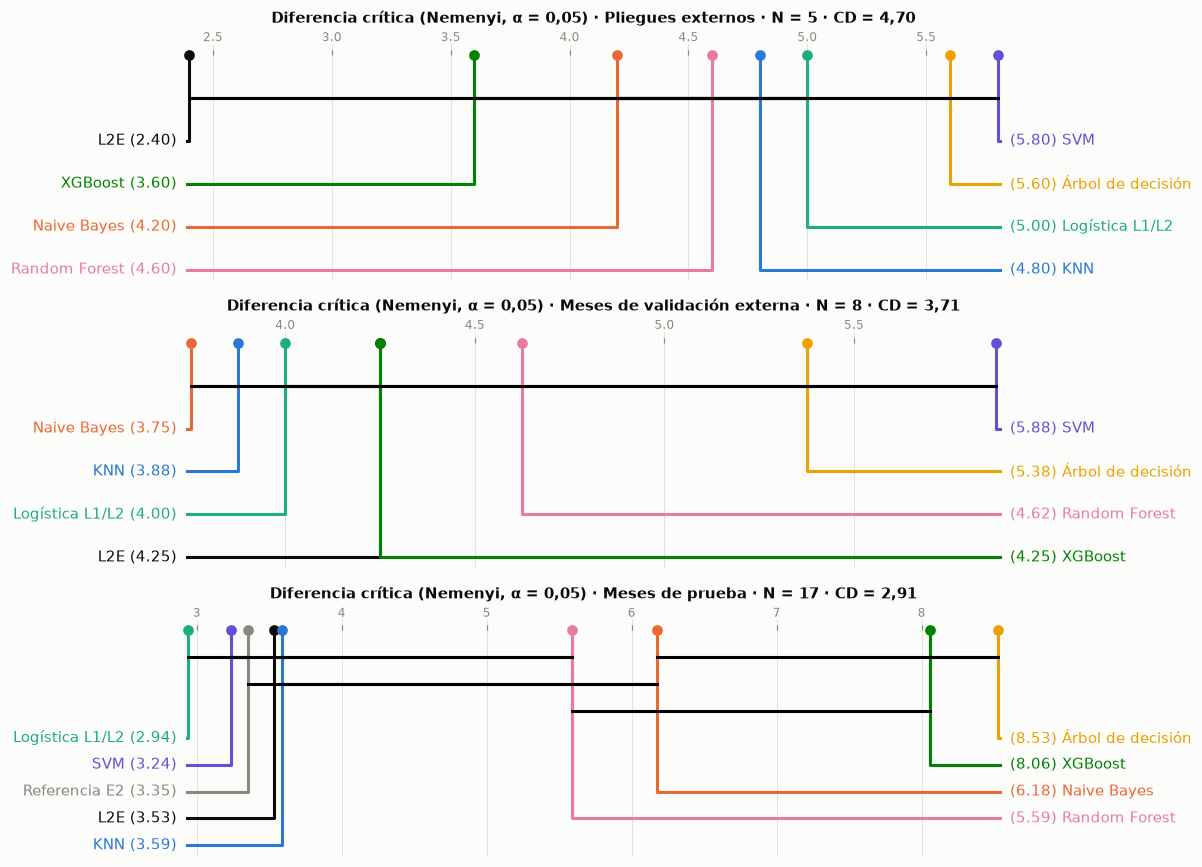

**Interpretación.** Con los cinco pliegues externos, el L2E tiene el mejor rango promedio (2,40), pero Friedman no rechaza la igualdad (p = 0,415) y la diferencia crítica es de 4,70 rangos; entre las 113 combinaciones queda en el rango 22,8. En los meses de prueba, Friedman rechaza la igualdad (p < 0,001), pero el L2E es 4.º en rango promedio (3,53), detrás de Logística L1/L2, SVM y Referencia E2, y Nemenyi no lo separa de Naive Bayes (p = 0,110).

Esto significa que las pruebas de Friedman y Nemenyi, que comparan rangos **dentro** de cada bloque, no muestran una superioridad del L2E: con cinco pliegues no hay potencia, y dentro de cada mes de prueba el L2E queda en el grupo de las mejores logísticas, la SVM y KNN, por delante de Naive Bayes y de los modelos de árboles en rango promedio. Hay que tener en cuenta lo que estas pruebas miden: dentro de un mes el nivel cambia poco, y el componente que da la ventaja al L2E es justamente el que sigue el nivel **entre** días y meses. Un modelo que ordena mejor a los clientes de un periodo y uno que, además, sabe qué periodos convierten más, se distinguen en el ordenamiento global, no dentro de cada bloque.

Por tanto, corresponde reportar este resultado como lo que es (la prueba global de rangos no rechaza la igualdad entre el L2E y la mejor combinación benchmark) y completar la evidencia con las pruebas pareadas de la sección {ref}`6.4 <sec-6-4>` y las pruebas sobre el ordenamiento global de la sección {ref}`6.5 <sec-6-5>`, sin cambiar la regla de decisión declarada en la sección {ref}`6.1 <sec-6-1>`.

In [18]:
M_pl = pd.DataFrame(ext)
M_pl.index = range(1, cfg.K_EXTERNO + 1)
M_mes_ext = pd.DataFrame({k: st4.metrica_por_bloque(g["y"], g["puntaje"], g["periodo"])
                          for k, g in oof.groupby("modelo")}).dropna()[["L2E"] + MODELOS]
M_mes_te = pd.DataFrame({k: st4.metrica_por_bloque(yte, PUNTAJE_TE[k], periodo_te.to_numpy()) for k in COMP}).dropna()
semana_te = dia_te // 5
M_sem_te = pd.DataFrame({k: st4.metrica_por_bloque(yte, PUNTAJE_TE[k], semana_te, min_registros=30)
                         for k in COMP}).dropna()
UNIVERSOS = {"Pliegues externos": M_pl, "Meses de validación externa": M_mes_ext, "Meses de prueba": M_mes_te,
             "Semanas de prueba": M_sem_te}

# Universo completo del tercer entregable: las 112 combinaciones de clasificación más el L2E, por pliegue
mat_all = pl_clf.pivot_table(index="pliegue", columns=["modelo", "balanceo", "optimizador"], values="auc_pr")
mat_all.columns = [" · ".join(c) for c in mat_all.columns]
mat_all["L2E"] = ext["L2E"]
fr_all = st.friedman(mat_all)

filas, NEM = [], {}
for nombre, M in UNIVERSOS.items():
    fr = st.friedman(M)
    nem = sp.posthoc_nemenyi_friedman(M.to_numpy())
    nem.index = nem.columns = M.columns
    NEM[nombre] = (fr, nem)
    rk = fr["rangos"]
    filas.append({"Universo": nombre, "Modelos (k)": M.shape[1], "Bloques (N)": M.shape[0], "χ²": fr["chi2"],
                  "p (Friedman)": pval(fr["p"]), "Diferencia crítica": st.diferencia_critica(M.shape[1], M.shape[0]),
                  "Rango del L2E": rk["L2E"], "Mejor rango": f"{CORTO[rk.index[0]]} ({num(rk.iloc[0], 2)})",
                  f"p Nemenyi L2E vs {CORTO[MEJOR]}": pval(nem.loc["L2E", MEJOR])})
filas.append({"Universo": "112 combinaciones + L2E (pliegues externos)", "Modelos (k)": mat_all.shape[1],
              "Bloques (N)": mat_all.shape[0], "χ²": fr_all["chi2"], "p (Friedman)": pval(fr_all["p"]),
              "Diferencia crítica": st.diferencia_critica(mat_all.shape[1], mat_all.shape[0]),
              "Rango del L2E": fr_all["rangos"]["L2E"],
              "Mejor rango": f"{fr_all['rangos'].index[0]} ({num(fr_all['rangos'].iloc[0], 2)})",
              f"p Nemenyi L2E vs {CORTO[MEJOR]}": "—"})
friedman_tab = pd.DataFrame(filas)
tabla(friedman_tab, dec=2, indice=False)

fig, axs = plt.subplots(3, 1, figsize=(11, 8))
for ax, nombre in zip(axs, ["Pliegues externos", "Meses de validación externa", "Meses de prueba"]):
    fr, nem = NEM[nombre]
    rangos = fr["rangos"].rename(index=CORTO)
    nem_c = nem.rename(index=CORTO, columns=CORTO)
    plt.sca(ax)
    sp.critical_difference_diagram(rangos, nem_c, ax=ax, label_fmt_left="{label} ({rank:.2f})  ",
                                   label_fmt_right="  ({rank:.2f}) {label}",
                                   color_palette={CORTO[k]: COLOR[k] for k in COMP})
    ax.set_title(f"Diferencia crítica (Nemenyi, α = 0,05) · {nombre} · N = {UNIVERSOS[nombre].shape[0]} · CD = "
                 f"{num(st.diferencia_critica(*UNIVERSOS[nombre].shape[::-1]), 2)}", fontsize=9.5)
plt.tight_layout()
plt.show()

r_te = NEM["Meses de prueba"][0]["rangos"]
interpretar(
    f"Con los cinco pliegues externos, el L2E tiene el mejor rango promedio ({num(NEM['Pliegues externos'][0]['rangos']['L2E'], 2)}), "
    f"pero Friedman no rechaza la igualdad ({p_txt(NEM['Pliegues externos'][0]['p'])}) y la diferencia crítica es de "
    f"{num(st.diferencia_critica(*M_pl.shape[::-1]), 2)} rangos; entre las 113 combinaciones queda en el rango "
    f"{num(fr_all['rangos']['L2E'], 1)}. En los meses de prueba, Friedman rechaza la igualdad ({p_txt(NEM['Meses de prueba'][0]['p'])}), "
    f"pero el L2E es {list(r_te.index).index('L2E') + 1}.º en rango promedio ({num(r_te['L2E'], 2)}), detrás de "
    f"{enumerar([CORTO[k] for k in r_te.index[:list(r_te.index).index('L2E')]])}, y Nemenyi no lo separa de "
    f"{CORTO[MEJOR]} (p = {num(NEM['Meses de prueba'][1].loc['L2E', MEJOR], 3)}).",
    conectar("Esto significa que", "Las pruebas de Friedman y Nemenyi, que comparan rangos **dentro** de cada bloque, "
             "no muestran una superioridad del L2E: con cinco pliegues no hay potencia, y dentro de cada mes de prueba "
             "el L2E queda en el grupo de las mejores logísticas, la SVM y KNN, por delante de Naive Bayes y de los "
             "modelos de árboles en rango promedio. Hay que "
             "tener en cuenta lo que estas pruebas miden: dentro de un mes el nivel cambia poco, y el componente que da "
             "la ventaja al L2E es justamente el que sigue el nivel **entre** días y meses. Un modelo que ordena mejor "
             "a los clientes de un periodo y uno que, además, sabe qué periodos convierten más, se distinguen en el "
             "ordenamiento global, no dentro de cada bloque."),
    conectar("Por tanto, corresponde", "Reportar este resultado como lo que es (la prueba global de rangos no rechaza "
             "la igualdad entre el L2E y la mejor combinación benchmark) y completar la evidencia con las pruebas "
             "pareadas de la sección 6.4 y las pruebas sobre el ordenamiento global de la sección 6.5, sin cambiar la "
             "regla de decisión declarada en la sección 6.1."))

(sec-6-4)=
## 6.4 Prueba 2: comparaciones pareadas (Wilcoxon, t corregida y prueba bayesiana)

In [19]:
filas = []
for nombre, M in UNIVERSOS.items():
    bloque = []
    for c in M.columns.drop("L2E"):
        d_ = M["L2E"] - M[c]
        p_ = stats.wilcoxon(M["L2E"], M[c]).pvalue if (d_ != 0).any() else 1.0
        bloque.append({"Universo": nombre, "Benchmark": c, "N": len(M), "Diferencia mediana": d_.median(),
                       "p Wilcoxon": p_, "δ de Cliff": st.delta_cliff(M["L2E"], M[c])})
    bloque = pd.DataFrame(bloque)
    bloque["p Holm"] = st.ajustar_p(bloque["p Wilcoxon"])
    filas.append(bloque)
wil = pd.concat(filas, ignore_index=True)

n_aj = [c["n_ent"] for c in corr["l2e"]]
n_va = [c["n_val"] for c in corr["l2e"]]
nb = pd.DataFrame([{"Benchmark": c, **st4.t_nadeau_bengio(M_pl["L2E"], M_pl[c], n_aj, n_va)} for c in MODELOS])
nb["p Holm"] = st.ajustar_p(nb["p"])
bay = pd.DataFrame([{"Benchmark": c, **st4.rangos_signo_bayes(M_mes_te["L2E"], M_mes_te[c], rope=0.01)}
                    for c in M_mes_te.columns.drop("L2E")])

piv = wil.assign(celda=lambda d: d.apply(lambda r: f"{pval(r['p Holm'])} ({num(r['δ de Cliff'], 2)})", axis=1))
piv = piv.pivot(index="Benchmark", columns="Universo", values="celda")[list(UNIVERSOS)]
piv["t Nadeau-Bengio, p Holm"] = nb.set_index("Benchmark")["p Holm"].map(pval)
piv["Bayesiana (meses de prueba): P(L2E mejor) / P(ROPE) / P(benchmark mejor)"] = bay.set_index("Benchmark").apply(
    lambda r: f"{num(r['p_a_mejor'], 2)} / {num(r['p_rope'], 2)} / {num(r['p_b_mejor'], 2)}", axis=1)
piv.index = [CORTO[i] for i in piv.index]
display(Markdown("Valor p de Wilcoxon ajustado por Holm y, entre paréntesis, δ de Cliff del L2E frente a cada benchmark:"))
tabla(piv, indice=True)

w_te = wil[wil["Universo"] == "Meses de prueba"].set_index("Benchmark")
w_se = wil[wil["Universo"] == "Semanas de prueba"].set_index("Benchmark")
sig_te = [CORTO[b] for b in w_te.index if w_te.loc[b, "p Holm"] < 0.05 and w_te.loc[b, "Diferencia mediana"] > 0]
bay_i = bay.set_index("Benchmark")
favor_bm = [b for b in bay_i.index if bay_i.loc[b, "p_b_mejor"] > 0.5]
interpretar(
    f"Frente a la mejor combinación benchmark, {CORTO[MEJOR]}, Wilcoxon da un p de Holm "
    f"{p_frase(w_te.loc[MEJOR, 'p Holm'])} en los {int(w_te.loc[MEJOR, 'N'])} meses de prueba y "
    f"{p_frase(w_se.loc[MEJOR, 'p Holm'])} en las {int(w_se.loc[MEJOR, 'N'])} semanas, con δ de Cliff de "
    f"{num(w_te.loc[MEJOR, 'δ de Cliff'], 3)} y {num(w_se.loc[MEJOR, 'δ de Cliff'], 3)}, y la prueba bayesiana asigna "
    f"una probabilidad de {num(bay.set_index('Benchmark').loc[MEJOR, 'p_a_mejor'], 2)} a que el L2E sea mejor. En los meses "
    f"de prueba, el L2E es significativamente mejor que {enumerar(sig_te)}; frente a los demás, la diferencia mediana es "
    f"cercana a cero. En los pliegues y meses de la validación externa ninguna comparación es significativa, y la prueba "
    f"t corregida da un p de Holm {p_frase(nb.set_index('Benchmark').loc[MEJOR, 'p Holm'])} frente a {CORTO[MEJOR]}. "
    + (f"Frente a {enumerar([CORTO[b] for b in favor_bm])}, en cambio, la prueba bayesiana asigna una probabilidad "
       f"mayor que 0,5 a que el benchmark sea mejor dentro de cada mes (entre "
       f"{num(bay_i.loc[favor_bm, 'p_b_mejor'].min(), 2)} y {num(bay_i.loc[favor_bm, 'p_b_mejor'].max(), 2)}), aunque "
       "Wilcoxon no detecta diferencias." if favor_bm else ""),
    conectar("Lo anterior indica que", "Las comparaciones pareadas confirman la lectura de la sección 6.3: dentro de cada "
             "periodo, el L2E supera con significancia y efecto pequeño a la mejor combinación del tercer entregable y "
             "a los modelos de árboles, pero no supera a las logísticas, la SVM y KNN: con ellas no hay diferencias "
             "significativas y, para algunas, la evidencia bayesiana se inclina levemente a favor del benchmark. En "
             "otras palabras, el L2E no ordena mejor a los clientes de un mismo mes que una buena logística. En la "
             "validación externa la "
             "falta de significancia se explica por el tamaño de muestra (cinco pliegues, ocho meses) y por los "
             "bloques de 2008, en los que ningún modelo discrimina."),
    conectar("Con base en esto, se propone", "Contar para la condición R3 la prueba de Wilcoxon en los meses de prueba "
             "frente a la mejor combinación benchmark, que es la unidad declarada en la sección 6.1, y presentar la "
             "falta de ventaja frente a las logísticas dentro de cada mes como un resultado del estudio, no como una "
             "debilidad que se oculte."))

Valor p de Wilcoxon ajustado por Holm y, entre paréntesis, δ de Cliff del L2E frente a cada benchmark:

Universo,Pliegues externos,Meses de validación externa,Meses de prueba,Semanas de prueba,"t Nadeau-Bengio, p Holm",Bayesiana (meses de prueba): P(L2E mejor) / P(ROPE) / P(benchmark mejor)
Árbol de decisión,"0,438 (0,36)","1,000 (0,09)","< 0,001 (0,58)","< 0,001 (0,51)","1,000","1,00 / 0,00 / 0,00"
Random Forest,"0,438 (0,36)","1,000 (0,00)","0,064 (0,16)","0,037 (0,11)","1,000","1,00 / 0,00 / 0,00"
KNN,"0,750 (0,12)","1,000 (0,03)","1,000 (-0,00)","1,000 (-0,02)","1,000","0,34 / 0,36 / 0,30"
Logística L1/L2,"0,625 (0,36)","1,000 (0,03)","1,000 (-0,03)","0,632 (-0,04)","1,000","0,03 / 0,36 / 0,61"
Naive Bayes,"0,750 (0,36)","1,000 (0,06)","< 0,001 (0,16)","< 0,001 (0,18)","1,000","1,00 / 0,00 / 0,00"
Referencia E2,—,—,"1,000 (-0,02)","1,000 (-0,06)",—,"0,20 / 0,21 / 0,59"
SVM,"0,750 (0,28)","1,000 (0,03)","1,000 (-0,00)","1,000 (-0,03)","1,000","0,27 / 0,05 / 0,69"
XGBoost,"0,750 (0,20)","1,000 (-0,03)","< 0,001 (0,48)","< 0,001 (0,40)","1,000","1,00 / 0,00 / 0,00"


**Interpretación.** Frente a la mejor combinación benchmark, Naive Bayes, Wilcoxon da un p de Holm menor que 0,001 en los 17 meses de prueba y menor que 0,001 en las 61 semanas, con δ de Cliff de 0,156 y 0,182, y la prueba bayesiana asigna una probabilidad de 1,00 a que el L2E sea mejor. En los meses de prueba, el L2E es significativamente mejor que Naive Bayes, XGBoost y Árbol de decisión; frente a los demás, la diferencia mediana es cercana a cero. En los pliegues y meses de la validación externa ninguna comparación es significativa, y la prueba t corregida da un p de Holm de 1,000 frente a Naive Bayes. Frente a Logística L1/L2, SVM y Referencia E2, en cambio, la prueba bayesiana asigna una probabilidad mayor que 0,5 a que el benchmark sea mejor dentro de cada mes (entre 0,59 y 0,69), aunque Wilcoxon no detecta diferencias.

Lo anterior indica que las comparaciones pareadas confirman la lectura de la sección {ref}`6.3 <sec-6-3>`: dentro de cada periodo, el L2E supera con significancia y efecto pequeño a la mejor combinación del tercer entregable y a los modelos de árboles, pero no supera a las logísticas, la SVM y KNN: con ellas no hay diferencias significativas y, para algunas, la evidencia bayesiana se inclina levemente a favor del benchmark. En otras palabras, el L2E no ordena mejor a los clientes de un mismo mes que una buena logística. En la validación externa la falta de significancia se explica por el tamaño de muestra (cinco pliegues, ocho meses) y por los bloques de 2008, en los que ningún modelo discrimina.

Con base en esto, se propone contar para la condición R3 la prueba de Wilcoxon en los meses de prueba frente a la mejor combinación benchmark, que es la unidad declarada en la sección {ref}`6.1 <sec-6-1>`, y presentar la falta de ventaja frente a las logísticas dentro de cada mes como un resultado del estudio, no como una debilidad que se oculte.

(sec-6-5)=
## 6.5 Prueba 3: ordenamiento global de la prueba (DeLong, *bootstrap* y permutación por días)

DeLong supone observaciones independientes. Antes de usarla se verifica ese supuesto con los residuos de la referencia del Entregable 2: si los registros de un mismo día comparten el nivel de conversión, los residuos tendrán media distinta entre días (ANOVA de un factor) y la serie de residuos medios diarios estará autocorrelacionada (Ljung-Box). Por eso DeLong se acompaña de dos procedimientos que tratan el día como unidad: el *bootstrap* estacionario, que remuestrea bloques de días consecutivos, y la permutación pareada, que intercambia los puntajes de los dos modelos día por día.

Residuos de,F (ANOVA por día),p (ANOVA),Autocorrelación diaria (rezago 1),p Ljung-Box (5 rezagos)
Referencia E2,"5,099","< 0,001","0,361","< 0,001"
L2E,"2,797","< 0,001","-0,126","0,068"


Benchmark,Δ AUC (DeLong),p Holm DeLong,Δ AUC-PR,IC 95 % Δ AUC-PR (bootstrap por días),p Holm bootstrap AUC-PR,IC 95 % Δ AUC (bootstrap por días),p Holm bootstrap AUC,p Holm permutación por días
Naive Bayes,"0,0573","< 0,001","0,0676","[0,035; 0,099]","0,008","[0,022; 0,092]","0,008","0,008"
Logística L1/L2,"0,0902","< 0,001","0,0721","[0,012; 0,101]","0,008","[0,005; 0,118]","0,024","0,008"
Random Forest,"0,0514","< 0,001","0,0984","[0,065; 0,124]","0,008","[0,035; 0,081]","0,008","0,008"
SVM,"0,0477","< 0,001","0,0635","[0,020; 0,089]","0,008","[0,010; 0,062]","0,024","0,008"
XGBoost,"0,2124","< 0,001","0,2326","[0,150; 0,288]","0,008","[0,138; 0,257]","0,008","0,008"
Árbol de decisión,"0,2047","< 0,001","0,2280","[0,157; 0,274]","0,008","[0,137; 0,237]","0,008","0,008"
KNN,"0,0836","< 0,001","0,1021","[0,038; 0,130]","0,008","[0,018; 0,103]","0,008","0,008"
Referencia E2,"0,0621","< 0,001","0,0534","[0,010; 0,077]","0,008","[0,007; 0,082]","0,024","0,008"


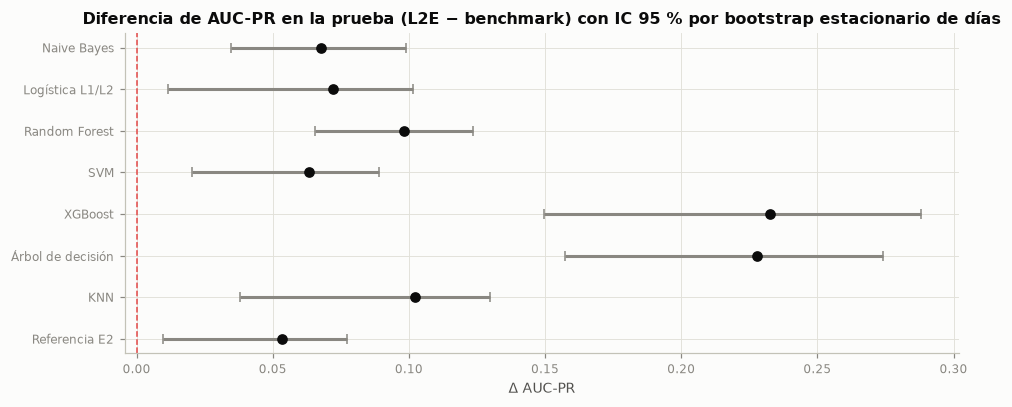

**Interpretación.** Los residuos de la referencia del Entregable 2 tienen media distinta entre días (F = 5,10, p < 0,001) y su serie diaria está autocorrelacionada (ρ₁ = 0,36); con el L2E el F baja a 2,80 y la autocorrelación a -0,13. Frente a los 8 benchmarks, la diferencia de AUC-PR va de 0,053 a 0,233, todos los intervalos por días excluyen el cero y el mayor p de Holm es de 0,008 en el *bootstrap* y de 0,008 en la permutación por días (el mínimo posible con 1000 réplicas y 8 comparaciones) y menor que 0,001 en DeLong. Frente a Naive Bayes, la ganancia es de 0,068 en AUC-PR y de 0,057 en AUC.

Esto quiere decir que el supuesto de independencia de DeLong no se cumple: los registros de un día comparten el nivel latente, que es precisamente lo que el L2E modela (sus residuos tienen mucha menos estructura diaria, aunque no desaparece). Aun así, las conclusiones no dependen de DeLong: el *bootstrap* y la permutación, que tratan el día como unidad y conservan esa dependencia, dan el mismo resultado. En el ordenamiento global de la prueba, que es lo que se usa para decidir a quién llamar en una campaña de varias semanas y lo que evaluó el tercer entregable, el L2E supera a todos los benchmarks, y la ventaja viene de ubicar mejor a los clientes de los días con más conversión.

De ahí que se opte por contar para R3 el *bootstrap* estacionario y la permutación por días como las pruebas válidas sobre el ordenamiento global, y DeLong solo como contraste, dejando explícito que su supuesto de independencia no se cumple.

In [20]:
from statsmodels.stats.diagnostic import acorr_ljungbox

supuesto = []
for k in ("referencia_e2", "L2E"):
    r_ = pd.DataFrame({"d": dia_te, "e": yte - PUNTAJE_TE[k]})
    grupos = [g["e"].to_numpy() for _, g in r_.groupby("d") if len(g) >= 2]
    serie = r_.groupby("d")["e"].mean()
    supuesto.append({"Residuos de": CORTO[k], "F (ANOVA por día)": stats.f_oneway(*grupos).statistic,
                     "p (ANOVA)": pval(stats.f_oneway(*grupos).pvalue),
                     "Autocorrelación diaria (rezago 1)": serie.autocorr(1),
                     "p Ljung-Box (5 rezagos)": pval(acorr_ljungbox(serie, lags=[5])["lb_pvalue"].iloc[0])})
tabla(pd.DataFrame(supuesto), dec=3, indice=False)

otros = COMP[1:]
dl = pd.DataFrame([{"Benchmark": k, **st.delong(yte, PUNTAJE_TE["L2E"], PUNTAJE_TE[k])} for k in otros])
dl["p Holm"] = st.ajustar_p(dl["p"])
bt_ap = st4.bootstrap_dias(yte, PUNTAJE_TE, dia_te, "L2E", average_precision_score, N_REP, LARGO)
bt_auc = st4.bootstrap_dias(yte, PUNTAJE_TE, dia_te, "L2E", roc_auc_score, N_REP, LARGO)
bt_ap["p Holm"], bt_auc["p Holm"] = st.ajustar_p(bt_ap["p"]), st.ajustar_p(bt_auc["p"])
pm = pd.DataFrame([{"Benchmark": k, **st4.permutacion_dias(yte, PUNTAJE_TE["L2E"], PUNTAJE_TE[k], dia_te, n_rep=N_REP)}
                   for k in otros])
pm["p Holm"] = st.ajustar_p(pm["p"])
glob_ = pd.DataFrame({
    "Benchmark": [CORTO[k] for k in otros],
    "Δ AUC (DeLong)": dl["diferencia"], "p Holm DeLong": dl["p Holm"].map(pval),
    "Δ AUC-PR": bt_ap["diferencia"].to_numpy(),
    "IC 95 % Δ AUC-PR (bootstrap por días)": [f"[{num(a, 3)}; {num(b, 3)}]" for a, b in zip(bt_ap["ic_inf"], bt_ap["ic_sup"])],
    "p Holm bootstrap AUC-PR": bt_ap["p Holm"].map(pval),
    "IC 95 % Δ AUC (bootstrap por días)": [f"[{num(a, 3)}; {num(b, 3)}]" for a, b in zip(bt_auc["ic_inf"], bt_auc["ic_sup"])],
    "p Holm bootstrap AUC": bt_auc["p Holm"].map(pval), "p Holm permutación por días": pm["p Holm"].map(pval)})
tabla(glob_, dec=4, indice=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(otros))
ax.errorbar(bt_ap["diferencia"], yy, xerr=[bt_ap["diferencia"] - bt_ap["ic_inf"], bt_ap["ic_sup"] - bt_ap["diferencia"]],
            fmt="o", color=TINTA, ecolor=GRIS, capsize=3)
ax.axvline(0, color=ROJO, lw=1, ls="--")
ax.set_yticks(yy, [CORTO[k] for k in otros])
ax.invert_yaxis()
ax.set(title="Diferencia de AUC-PR en la prueba (L2E − benchmark) con IC 95 % por bootstrap estacionario de días",
       xlabel="Δ AUC-PR")
plt.tight_layout()
plt.show()

sup_ref = supuesto[0]
interpretar(
    f"Los residuos de la referencia del Entregable 2 tienen media distinta entre días (F = "
    f"{num(sup_ref['F (ANOVA por día)'], 2)}, p {sup_ref['p (ANOVA)'] if sup_ref['p (ANOVA)'].startswith('<') else '= ' + sup_ref['p (ANOVA)']}) "
    f"y su serie diaria está autocorrelacionada (ρ₁ = {num(sup_ref['Autocorrelación diaria (rezago 1)'], 2)}); con el L2E "
    f"el F baja a {num(supuesto[1]['F (ANOVA por día)'], 2)} y la autocorrelación a "
    f"{num(supuesto[1]['Autocorrelación diaria (rezago 1)'], 2)}. Frente a los "
    f"{len(otros)} benchmarks, la diferencia de AUC-PR va de {num(bt_ap['diferencia'].min(), 3)} a "
    f"{num(bt_ap['diferencia'].max(), 3)}, todos los intervalos por días excluyen el cero y el mayor p de Holm es "
    f"{p_frase(bt_ap['p Holm'].max())} en el *bootstrap* y {p_frase(pm['p Holm'].max())} en la permutación por días (el "
    f"mínimo posible con {N_REP} réplicas y 8 comparaciones) y {p_frase(dl['p Holm'].max())} en DeLong. Frente a {CORTO[MEJOR]}, la ganancia es de "
    f"{num(bt_ap.set_index('modelo').loc[MEJOR, 'diferencia'], 3)} en AUC-PR y de "
    f"{num(dl.set_index('Benchmark').loc[MEJOR, 'diferencia'], 3)} en AUC.",
    conectar("Esto quiere decir que", "El supuesto de independencia de DeLong no se cumple: los registros de un día "
             "comparten el nivel latente, que es precisamente lo que el L2E modela (sus residuos tienen mucha menos "
             "estructura diaria, aunque no desaparece). Aun así, las conclusiones no dependen de DeLong: el *bootstrap* y la permutación, "
             "que tratan el día como unidad y conservan esa dependencia, dan el mismo resultado. En el ordenamiento "
             "global de la prueba, que es lo que se usa para decidir a quién llamar en una campaña de varias semanas y "
             "lo que evaluó el tercer entregable, el L2E supera a todos los benchmarks, y la ventaja viene de ubicar "
             "mejor a los clientes de los días con más conversión."),
    conectar("De ahí que se opte por", "Contar para R3 el *bootstrap* estacionario y la permutación por días como las "
             "pruebas válidas sobre el ordenamiento global, y DeLong solo como contraste, dejando explícito que su "
             "supuesto de independencia no se cumple."))

(sec-6-6)=
## 6.6 Prueba complementaria: calidad de las probabilidades (Diebold-Mariano)

El AUC-PR solo evalúa el orden. Para decisiones que dependen del valor de la probabilidad (cuántas suscripciones dará una lista de llamadas), se compara el Brier medio diario con Diebold-Mariano y la corrección HLN, que usa una varianza robusta a la autocorrelación; antes se verifica con Dickey-Fuller aumentada que la serie de diferencias de pérdida es estacionaria, supuesto de la prueba.

In [21]:
from statsmodels.tsa.stattools import adfuller

filas = []
for k in [k for k in COMP[1:] if ES_PROBA[k]]:
    d_ = pd.DataFrame({"d": dia_te, "a": (PUNTAJE_TE["L2E"] - yte) ** 2, "b": (PUNTAJE_TE[k] - yte) ** 2}).groupby("d").mean()
    dm = st.diebold_mariano(np.sqrt(d_["b"]), np.sqrt(d_["a"]))
    filas.append({"Benchmark": CORTO[k], "Brier L2E": d_["a"].mean(), "Brier benchmark": d_["b"].mean(),
                  "DM (HLN)": dm["DM_HLN"], "p": dm["p"], "p ADF (estacionariedad)": adfuller(d_["b"] - d_["a"])[1]})
dmt = pd.DataFrame(filas)
dmt["p Holm"] = st.ajustar_p(dmt["p"])
tabla(dmt.assign(**{c: dmt[c].map(pval) for c in ("p", "p Holm", "p ADF (estacionariedad)")}), dec=4, indice=False)
interpretar(
    f"El Brier medio diario del L2E es de {num(dmt['Brier L2E'].iloc[0], 3)}, frente a valores entre "
    f"{num(dmt['Brier benchmark'].min(), 3)} y {num(dmt['Brier benchmark'].max(), 3)} de los benchmarks; Diebold-Mariano "
    f"rechaza la igualdad frente a todos (mayor p de Holm: {pval(dmt['p Holm'].max())}) y la serie de diferencias es "
    f"estacionaria en todos los casos (mayor p de ADF: {pval(dmt['p ADF (estacionariedad)'].max())}).",
    conectar("Hay que tener en cuenta que", "Esta prueba favorece por diseño al L2E, porque los benchmarks se calibraron "
             "con la prevalencia del entrenamiento y los balanceados desplazan sus probabilidades hacia 0,5; por eso no "
             "se cuenta entre las pruebas de la condición R3, que se refieren al orden de los clientes. Lo que sí "
             "muestra es una ventaja práctica: las probabilidades del L2E siguen la tasa vigente sin una recalibración "
             "aparte."),
    conectar("Por ello, se recomienda", "Usar directamente las probabilidades del L2E para estimar resultados de "
             "campaña, en lugar de recalibrar cada mes los modelos estáticos."))

Benchmark,Brier L2E,Brier benchmark,DM (HLN),p,p ADF (estacionariedad),p Holm
Naive Bayes,"0,2115","0,4594","19,2893","< 0,001","< 0,001","< 0,001"
Logística L1/L2,"0,2115","0,2830","9,3363","< 0,001","< 0,001","< 0,001"
Random Forest,"0,2115","0,2810","10,1728","< 0,001","< 0,001","< 0,001"
XGBoost,"0,2115","0,2681","10,5674","< 0,001","< 0,001","< 0,001"
Árbol de decisión,"0,2115","0,3449","14,2713","< 0,001","< 0,001","< 0,001"
KNN,"0,2115","0,2791","9,5490","< 0,001","< 0,001","< 0,001"
Referencia E2,"0,2115","0,2724","9,3116","< 0,001","< 0,001","< 0,001"


**Interpretación.** El Brier medio diario del L2E es de 0,212, frente a valores entre 0,268 y 0,459 de los benchmarks; Diebold-Mariano rechaza la igualdad frente a todos (mayor p de Holm: < 0,001) y la serie de diferencias es estacionaria en todos los casos (mayor p de ADF: < 0,001).

Hay que tener en cuenta que esta prueba favorece por diseño al L2E, porque los benchmarks se calibraron con la prevalencia del entrenamiento y los balanceados desplazan sus probabilidades hacia 0,5; por eso no se cuenta entre las pruebas de la condición R3, que se refieren al orden de los clientes. Lo que sí muestra es una ventaja práctica: las probabilidades del L2E siguen la tasa vigente sin una recalibración aparte.

Por ello, se recomienda usar directamente las probabilidades del L2E para estimar resultados de campaña, en lugar de recalibrar cada mes los modelos estáticos.

(sec-6-7)=
## 6.7 Tabla de pruebas de hipótesis y conteo para la condición R3

La tabla sigue el formato de la guía (sección {ref}`6.3 <sec-6-3>`) para la comparación principal, el L2E frente a la mejor combinación benchmark, y el resumen final cuenta, para cada benchmark, cuántas de las pruebas declaradas rechazan la igualdad.

In [22]:
fr_te, nem_te = NEM["Meses de prueba"]
ref_ = MEJOR
pt = [
    {"Prueba": "Friedman + Nemenyi (meses de prueba)", "H0": "Igual rango medio de los 9 modelos",
     "Supuestos verificados": "Bloques mensuales consecutivos y modelos fijos; comparación de rangos sin supuesto de escala",
     "Estadístico": f"χ² = {num(fr_te['chi2'], 2)}", "p crudo": nem_te.loc["L2E", ref_],
     "p ajustado": nem_te.loc["L2E", ref_], "Efecto": f"Δ rango = {num(fr_te['rangos'][ref_] - fr_te['rangos']['L2E'], 2)}",
     "unidad_r3": True},
    {"Prueba": "Wilcoxon pareado (meses de prueba)", "H0": "Mediana de las diferencias de AUC-PR igual a 0",
     "Supuestos verificados": "Diferencias pareadas por mes; simetría aproximada (prueba de rangos)",
     "Estadístico": f"mediana Δ = {num(w_te.loc[ref_, 'Diferencia mediana'], 3)}", "p crudo": w_te.loc[ref_, "p Wilcoxon"],
     "p ajustado": w_te.loc[ref_, "p Holm"], "Efecto": f"δ = {num(w_te.loc[ref_, 'δ de Cliff'], 3)}", "unidad_r3": True},
    {"Prueba": "Bootstrap estacionario por días (Δ AUC-PR)", "H0": "Δ AUC-PR = 0",
     "Supuestos verificados": f"Dependencia dentro del día y entre días (bloques de {num(LARGO, 1)} días en promedio)",
     "Estadístico": f"Δ = {num(bt_ap.set_index('modelo').loc[ref_, 'diferencia'], 3)}",
     "p crudo": bt_ap.set_index("modelo").loc[ref_, "p"], "p ajustado": bt_ap.set_index("modelo").loc[ref_, "p Holm"],
     "Efecto": f"IC 95 % [{num(bt_ap.set_index('modelo').loc[ref_, 'ic_inf'], 3)}; {num(bt_ap.set_index('modelo').loc[ref_, 'ic_sup'], 3)}]",
     "unidad_r3": True},
    {"Prueba": "Permutación pareada por días (Δ AUC-PR)", "H0": "Los dos modelos son intercambiables",
     "Supuestos verificados": "Intercambiabilidad bajo H0; se permutan días completos",
     "Estadístico": f"Δ = {num(pm.set_index('Benchmark').loc[ref_, 'diferencia'], 3)} (rangos)",
     "p crudo": pm.set_index("Benchmark").loc[ref_, "p"], "p ajustado": pm.set_index("Benchmark").loc[ref_, "p Holm"],
     "Efecto": "—", "unidad_r3": True},
    {"Prueba": "DeLong (AUC de prueba)", "H0": "AUC iguales", "Supuestos verificados":
     "Independencia de observaciones: no se cumple (sección 6.5); solo contraste",
     "Estadístico": f"z = {num(dl.set_index('Benchmark').loc[ref_, 'z'], 2)}", "p crudo": dl.set_index("Benchmark").loc[ref_, "p"],
     "p ajustado": dl.set_index("Benchmark").loc[ref_, "p Holm"],
     "Efecto": f"Δ AUC = {num(dl.set_index('Benchmark').loc[ref_, 'diferencia'], 3)}", "unidad_r3": False},
    {"Prueba": "Wilcoxon pareado (pliegues externos)", "H0": "Mediana de las diferencias igual a 0",
     "Supuestos verificados": "Cinco bloques: potencia insuficiente (p mínimo 0,0625)",
     "Estadístico": f"mediana Δ = {num(wil[(wil['Universo'] == 'Pliegues externos') & (wil['Benchmark'] == ref_)]['Diferencia mediana'].iloc[0], 3)}",
     "p crudo": wil[(wil["Universo"] == "Pliegues externos") & (wil["Benchmark"] == ref_)]["p Wilcoxon"].iloc[0],
     "p ajustado": wil[(wil["Universo"] == "Pliegues externos") & (wil["Benchmark"] == ref_)]["p Holm"].iloc[0],
     "Efecto": f"δ = {num(st.delta_cliff(M_pl['L2E'], M_pl[ref_]), 3)}", "unidad_r3": False},
    {"Prueba": "t corregida de Nadeau-Bengio (pliegues externos)", "H0": "Diferencia media igual a 0",
     "Supuestos verificados": f"Normalidad de las 5 diferencias (Shapiro p = {num(stats.shapiro(M_pl['L2E'] - M_pl[ref_]).pvalue, 3)})",
     "Estadístico": f"t = {num(nb.set_index('Benchmark').loc[ref_, 't'], 2)}", "p crudo": nb.set_index("Benchmark").loc[ref_, "p"],
     "p ajustado": nb.set_index("Benchmark").loc[ref_, "p Holm"], "Efecto": f"d̄ = {num(nb.set_index('Benchmark').loc[ref_, 'dif_media'], 4)}",
     "unidad_r3": False},
    {"Prueba": "Diebold-Mariano HLN (Brier diario)", "H0": "Igual pérdida esperada",
     "Supuestos verificados": "Diferencias de pérdida estacionarias (ADF)",
     "Estadístico": f"DM = {num(dmt.set_index('Benchmark').loc[CORTO[ref_], 'DM (HLN)'], 2)}" if CORTO[ref_] in dmt["Benchmark"].values else "—",
     "p crudo": dmt.set_index("Benchmark").loc[CORTO[ref_], "p"] if CORTO[ref_] in dmt["Benchmark"].values else np.nan,
     "p ajustado": dmt.set_index("Benchmark").loc[CORTO[ref_], "p Holm"] if CORTO[ref_] in dmt["Benchmark"].values else np.nan,
     "Efecto": "—", "unidad_r3": False},
]
pt = pd.DataFrame(pt)
pt["Conclusión"] = np.where(pt["p ajustado"] < 0.05, "Se rechaza H0 (L2E mejor)", "No se rechaza H0")
tabla(pt.drop(columns="unidad_r3").assign(**{"p crudo": pt["p crudo"].map(pval), "p ajustado": pt["p ajustado"].map(pval)}),
      indice=False)

conteo = []
for k in COMP[1:]:
    pruebas_k = {"Nemenyi (meses)": nem_te.loc["L2E", k], "Wilcoxon (meses)": w_te.loc[k, "p Holm"],
                 "Bootstrap por días": bt_ap.set_index("modelo").loc[k, "p Holm"],
                 "Permutación por días": pm.set_index("Benchmark").loc[k, "p Holm"]}
    favor = w_te.loc[k, "Diferencia mediana"] > 0
    conteo.append({"Benchmark": CORTO[k], **{n: pval(v) for n, v in pruebas_k.items()},
                   "Pruebas que rechazan (p < 0,05)": int(sum(v < 0.05 for v in pruebas_k.values())),
                   "δ de Cliff (meses)": w_te.loc[k, "δ de Cliff"]})
conteo = pd.DataFrame(conteo)
tabla(conteo, dec=3, indice=False)
para_guion("conteo_r3", conteo)
para_guion("pruebas_r3", pt.assign(**{"p crudo": pt["p crudo"].astype(float), "p ajustado": pt["p ajustado"].astype(float)}))
n_r3 = int(pt.loc[pt["unidad_r3"], "p ajustado"].lt(0.05).sum())
interpretar(
    f"Frente a la mejor combinación benchmark, {CORTO[MEJOR]}, {n_r3} de las 4 pruebas declaradas para R3 rechazan la "
    f"igualdad con p ajustado < 0,05 (Wilcoxon en meses, bootstrap y permutación por días{'' if nem_te.loc['L2E', MEJOR] >= 0.05 else ' y Nemenyi'}), "
    f"con un δ de Cliff de {num(w_te.loc[MEJOR, 'δ de Cliff'], 3)} sobre los meses de prueba. Frente al resto, el "
    f"número de pruebas que rechazan va de {conteo['Pruebas que rechazan (p < 0,05)'].min()} a "
    f"{conteo['Pruebas que rechazan (p < 0,05)'].max()}: las pruebas globales rechazan frente a todos, y las de rangos por "
    f"mes solo frente a {enumerar(sig_te)}.",
    conectar("En síntesis,", "La evidencia es consistente con un mecanismo concreto: el L2E iguala a las mejores "
             "logísticas en el orden de los clientes de un mismo periodo y les gana en el ordenamiento global porque "
             "sigue el nivel de conversión entre días. Frente a la mejor combinación del tercer entregable gana en las "
             "dos dimensiones."),
    conectar("Así las cosas, se decide", "Evaluar la condición R3 con estos conteos en la sección 6.12, después de "
             "descartar en las secciones 6.8 a 6.10 que la ventaja dependa de una ventaja de información, de unos "
             "hiperparámetros particulares o de este conjunto de datos."))

Prueba,H0,Supuestos verificados,Estadístico,p crudo,p ajustado,Efecto,Conclusión
Friedman + Nemenyi (meses de prueba),Igual rango medio de los 9 modelos,Bloques mensuales consecutivos y modelos fijos; comparación de rangos sin supuesto de escala,"χ² = 85,60","0,110","0,110","Δ rango = 2,65",No se rechaza H0
Wilcoxon pareado (meses de prueba),Mediana de las diferencias de AUC-PR igual a 0,Diferencias pareadas por mes; simetría aproximada (prueba de rangos),"mediana Δ = 0,033","< 0,001","< 0,001","δ = 0,156",Se rechaza H0 (L2E mejor)
Bootstrap estacionario por días (Δ AUC-PR),Δ AUC-PR = 0,"Dependencia dentro del día y entre días (bloques de 12,5 días en promedio)","Δ = 0,068","0,001","0,008","IC 95 % [0,035; 0,099]",Se rechaza H0 (L2E mejor)
Permutación pareada por días (Δ AUC-PR),Los dos modelos son intercambiables,Intercambiabilidad bajo H0; se permutan días completos,"Δ = 0,068 (rangos)","< 0,001","0,008",—,Se rechaza H0 (L2E mejor)
DeLong (AUC de prueba),AUC iguales,Independencia de observaciones: no se cumple (sección 6.5); solo contraste,"z = 11,38","< 0,001","< 0,001","Δ AUC = 0,057",Se rechaza H0 (L2E mejor)
Wilcoxon pareado (pliegues externos),Mediana de las diferencias igual a 0,"Cinco bloques: potencia insuficiente (p mínimo 0,0625)","mediana Δ = 0,004","0,188","0,750","δ = 0,360",No se rechaza H0
t corregida de Nadeau-Bengio (pliegues externos),Diferencia media igual a 0,"Normalidad de las 5 diferencias (Shapiro p = 0,361)","t = 0,97","0,388","1,000","d̄ = 0,0079",No se rechaza H0
Diebold-Mariano HLN (Brier diario),Igual pérdida esperada,Diferencias de pérdida estacionarias (ADF),"DM = 19,29","< 0,001","< 0,001",—,Se rechaza H0 (L2E mejor)


Benchmark,Nemenyi (meses),Wilcoxon (meses),Bootstrap por días,Permutación por días,"Pruebas que rechazan (p < 0,05)",δ de Cliff (meses)
Naive Bayes,"0,110","< 0,001","0,008","0,008",3,"0,156"
Logística L1/L2,"0,999","1,000","0,008","0,008",2,"-0,031"
Random Forest,"0,411","0,064","0,008","0,008",2,"0,163"
SVM,"1,000","1,000","0,008","0,008",2,"-0,003"
XGBoost,"< 0,001","< 0,001","0,008","0,008",4,"0,481"
Árbol de decisión,"< 0,001","< 0,001","0,008","0,008",4,"0,585"
KNN,"1,000","1,000","0,008","0,008",2,"-0,003"
Referencia E2,"1,000","1,000","0,008","0,008",2,"-0,017"


**Interpretación.** Frente a la mejor combinación benchmark, Naive Bayes, 3 de las 4 pruebas declaradas para R3 rechazan la igualdad con p ajustado < 0,05 (Wilcoxon en meses, bootstrap y permutación por días), con un δ de Cliff de 0,156 sobre los meses de prueba. Frente al resto, el número de pruebas que rechazan va de 2 a 4: las pruebas globales rechazan frente a todos, y las de rangos por mes solo frente a Naive Bayes, XGBoost y Árbol de decisión.

En síntesis, la evidencia es consistente con un mecanismo concreto: el L2E iguala a las mejores logísticas en el orden de los clientes de un mismo periodo y les gana en el ordenamiento global porque sigue el nivel de conversión entre días. Frente a la mejor combinación del tercer entregable gana en las dos dimensiones.

Así las cosas, se decide evaluar la condición R3 con estos conteos en la sección {ref}`6.12 <sec-6-12>`, después de descartar en las secciones {ref}`6.8 <sec-6-8>` a {ref}`6.10 <sec-6-10>` que la ventaja dependa de una ventaja de información, de unos hiperparámetros particulares o de este conjunto de datos.

(sec-6-8)=
## 6.8 Controles con igual información y métodos del estado del arte

El L2E usa las etiquetas de los días cerrados y los benchmarks no; una comparación justa debe separar el aporte del **mecanismo** del aporte de la **información**. Para eso, cada benchmark recibe las mismas etiquetas diferidas por tres vías: (a) el componente C2 aislado (`filtrar_nivel`), que filtra un nivel latente sobre su logit con el $q_u$ que eligió el L2E en el mismo pliegue o en el modelo final, sin ver la validación; (b) la recalibración mensual del intercepto del tercer entregable; y (c), como método reciente sin etiquetas, el EM de Saerens et al. ({cite:year}`saerens2002`), equivalente al MLLS de Garg et al. ({cite:year}`garg2020`), aplicado a cada día sobre la referencia del Entregable 2. La logística dinámica de una sola escala (McCormick et al., {cite:year}`mccormick2012`) es la variante `escala_unica` de la ablación.

In [23]:
q_final = L2E["params"]["modelo__q_nivel"]
filas = []
for k in COMP[1:]:
    s_ = PUNTAJE_TE[k]
    f_ = fin_e3[f"clf_{k}"]
    filas.append({"Modelo": CORTO[k], "Variante": "Sin información adicional", "AUC-PR": ap_te[k], "AUC": auc_te[k],
                  "puntaje": s_})
    s_c2 = filtrar_nivel(s_, dia_te, yte, q_final, es_probabilidad=ES_PROBA[k])
    filas.append({"Modelo": CORTO[k], "Variante": "+ filtro de nivel C2", "AUC-PR": average_precision_score(yte, s_c2),
                  "AUC": roc_auc_score(yte, s_c2), "puntaje": s_c2})
    if ES_PROBA[k]:
        s_m = evm.recalibracion_mensual(s_, yte, periodo_te.to_numpy(), f_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult])
        filas.append({"Modelo": CORTO[k], "Variante": "+ recalibración mensual (E3)",
                      "AUC-PR": average_precision_score(yte, s_m), "AUC": roc_auc_score(yte, s_m), "puntaje": s_m})
s_em = em_por_dia(PUNTAJE_TE["referencia_e2"], dia_te, y_tr.mean())
filas.append({"Modelo": CORTO["referencia_e2"], "Variante": "+ EM/MLLS por día (sin etiquetas)",
              "AUC-PR": average_precision_score(yte, s_em), "AUC": roc_auc_score(yte, s_em), "puntaje": s_em})
for v in ("escala_unica", "sin_pendientes", "l2e"):
    filas.append({"Modelo": "L2E", "Variante": NOMBRE_VARIANTE[v], "AUC-PR": fin_l2e[v]["auc_pr"],
                  "AUC": fin_l2e[v]["auc"], "puntaje": fin_l2e[v]["puntaje_te"]})
ctrl = pd.DataFrame(filas)
piv_c = ctrl.pivot_table(index="Modelo", columns="Variante", values="AUC-PR", sort=False)
tabla(piv_c, dec=3)

# Bucle externo: el mismo filtro C2 sobre las predicciones fuera de muestra de cada finalista
ext_c2 = {}
for m in MODELOS:
    vals = []
    for c in corr["l2e"]:
        g = oof[(oof["modelo"] == m) & (oof["pliegue"] == c["pliegue"])].sort_values("indice")
        vals.append(average_precision_score(g["y"], filtrar_nivel(g["puntaje"].to_numpy(), g["dia"].to_numpy(), g["y"].to_numpy(),
                                                                  c["params"]["modelo__q_nivel"], es_probabilidad=fin_e3[f"clf_{m}"]["es_proba"])))
    ext_c2[m] = np.array(vals)
ext_ctrl = pd.DataFrame({"AUC-PR externo sin información adicional": {CORTO[m]: ext[m].mean() for m in MODELOS},
                         "AUC-PR externo + filtro C2": {CORTO[m]: ext_c2[m].mean() for m in MODELOS}})
ext_ctrl.loc["L2E"] = [ext["L2E"].mean(), ext["L2E"].mean()]
tabla(ext_ctrl, dec=4)

otros_ctrl = ctrl[ctrl["Modelo"] != "L2E"]
mejor_c = otros_ctrl.loc[otros_ctrl["AUC-PR"].idxmax()]
bt_c = st4.bootstrap_dias(yte, {"L2E": L2E["puntaje_te"], "control": mejor_c["puntaje"]}, dia_te, "L2E",
                          average_precision_score, N_REP, LARGO).iloc[0]
c2_gana = sum(piv_c.loc[CORTO[k], "+ filtro de nivel C2"] > piv_c.loc[CORTO[k], "Sin información adicional"] for k in COMP[1:])
con_mensual = [CORTO[k] for k in COMP[1:] if ES_PROBA[k]]
c2_vs_mensual = [m for m in con_mensual if piv_c.loc[m, "+ filtro de nivel C2"] > piv_c.loc[m, "+ recalibración mensual (E3)"]]
mensual_gana = [m for m in con_mensual if m not in c2_vs_mensual]
interpretar(
    f"El filtro C2 mejora el AUC-PR de prueba de {c2_gana} de los {len(COMP) - 1} benchmarks; el mejor control es "
    f"{mejor_c['Modelo']} {mejor_c['Variante']}, con {num(mejor_c['AUC-PR'], 3)}, frente a {num(ap_te['L2E'], 3)} del "
    f"L2E (Δ = {num(bt_c['diferencia'], 3)}, IC 95 % [{num(bt_c['ic_inf'], 3)}; {num(bt_c['ic_sup'], 3)}], p = "
    f"{pval(bt_c['p'])}). El filtro diario supera a la recalibración mensual en {len(c2_vs_mensual)} de los "
    f"{len(con_mensual)} modelos con probabilidades"
    + (f" (la mensual es mejor en {enumerar(mensual_gana)})" if mensual_gana else "") +
    f", y el EM sin etiquetas sobre la referencia del E2 obtiene {num(average_precision_score(yte, s_em), 3)}. "
    f"En el bucle externo, el mejor benchmark con el filtro C2 llega a {num(ext_ctrl.iloc[:-1, 1].max(), 4)}, frente a "
    f"{num(ext['L2E'].mean(), 4)} del L2E.",
    conectar("Esto significa que", "La mayor parte de la ventaja del L2E la explica su componente central, el nivel "
             "filtrado con etiquetas diferidas, y ese componente es **transferible**: aplicado como envoltorio a otros "
             "modelos también los mejora en la mayoría de los casos, en general más que la recalibración mensual que "
             "sugirió el docente y que la corrección sin etiquetas. "
             + ("Frente al mejor de esos híbridos, el L2E no muestra una diferencia significativa en la prueba, de modo "
                "que la contribución propia de las pendientes dinámicas y del ajuste conjunto es pequeña en este "
                "problema." if bt_c["p"] >= 0.05 else
                "Aun frente al mejor de esos híbridos el L2E conserva una diferencia significativa, que corresponde a "
                "las pendientes dinámicas y al ajuste conjunto del nivel.")),
    conectar("Por lo anterior, conviene", "Presentar la contribución en dos niveles: un modelo completo (L2E) que supera a "
             "los benchmarks del proyecto, y un mecanismo general (el filtro de nivel con etiquetas diferidas) que "
             "cualquier modelo de propensión puede incorporar; y documentar que esta ventaja exige que las etiquetas "
             "de cada día estén disponibles al día siguiente (sección 6.9)."))

Variante,Sin información adicional,+ filtro de nivel C2,+ recalibración mensual (E3),+ EM/MLLS por día (sin etiquetas),Una sola escala (q_β = q_u),Sin actualizar pendientes (C3),L2E completo
Modelo,,,,,,,
Naive Bayes,"0,534","0,479","0,478",—,—,—,—
Logística L1/L2,"0,530","0,578","0,584",—,—,—,—
Random Forest,"0,503","0,547","0,541",—,—,—,—
SVM,"0,538","0,529",—,—,—,—,—
XGBoost,"0,369","0,487","0,482",—,—,—,—
Árbol de decisión,"0,374","0,454","0,423",—,—,—,—
KNN,"0,500","0,557","0,577",—,—,—,—
Referencia E2,"0,548","0,594","0,579","0,524",—,—,—
L2E,—,—,—,—,"0,593","0,571","0,602"


,AUC-PR externo sin información adicional,AUC-PR externo + filtro C2
Naive Bayes,"0,1028","0,0934"
Logística L1/L2,"0,0955","0,0886"
Random Forest,"0,0952","0,1034"
SVM,"0,0923","0,0899"
XGBoost,"0,0905","0,0951"
Árbol de decisión,"0,0856","0,0860"
KNN,"0,0842","0,0924"
L2E,"0,1107","0,1107"


**Interpretación.** El filtro C2 mejora el AUC-PR de prueba de 6 de los 8 benchmarks; el mejor control es Referencia E2 + filtro de nivel C2, con 0,594, frente a 0,602 del L2E (Δ = 0,008, IC 95 % [-0,001; 0,017], p = 0,070). El filtro diario supera a la recalibración mensual en 5 de los 7 modelos con probabilidades (la mensual es mejor en Logística L1/L2 y KNN), y el EM sin etiquetas sobre la referencia del E2 obtiene 0,524. En el bucle externo, el mejor benchmark con el filtro C2 llega a 0,1034, frente a 0,1107 del L2E.

Esto significa que la mayor parte de la ventaja del L2E la explica su componente central, el nivel filtrado con etiquetas diferidas, y ese componente es **transferible**: aplicado como envoltorio a otros modelos también los mejora en la mayoría de los casos, en general más que la recalibración mensual que sugirió el docente y que la corrección sin etiquetas. Frente al mejor de esos híbridos, el L2E no muestra una diferencia significativa en la prueba, de modo que la contribución propia de las pendientes dinámicas y del ajuste conjunto es pequeña en este problema.

Por lo anterior, conviene presentar la contribución en dos niveles: un modelo completo (L2E) que supera a los benchmarks del proyecto, y un mecanismo general (el filtro de nivel con etiquetas diferidas) que cualquier modelo de propensión puede incorporar; y documentar que esta ventaja exige que las etiquetas de cada día estén disponibles al día siguiente (sección {ref}`6.9 <sec-6-9>`).

(sec-6-9)=
## 6.9 Robustez, sensibilidad y análisis de errores

Se evalúa si el resultado depende de unos hiperparámetros particulares (rejilla de $q_u$ y $q_\beta$ y barrido de $\lambda$, sin reoptimizar), de la demora de las etiquetas (de 1 a 40 días), del ruido en las etiquetas, del tamaño de la ventana de entrenamiento y de la semilla del optimizador. Todo sale de `scripts/ejecutar_analisis.py`.

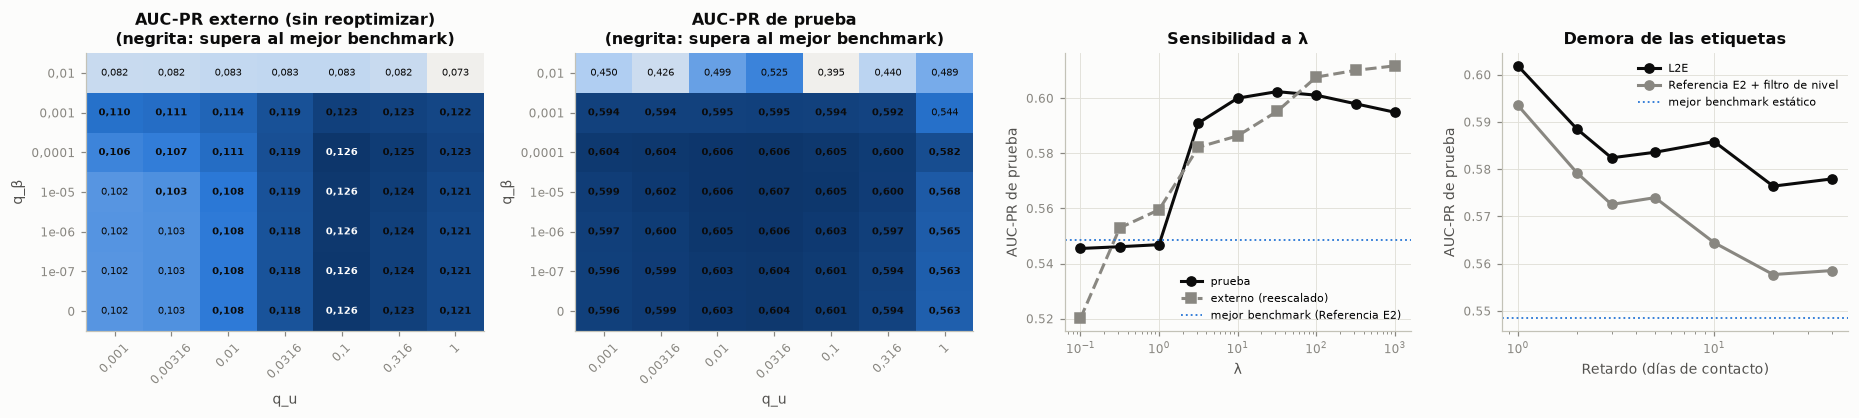

Semilla del optimizador,AUC-PR externo,AUC-PR prueba,AUC prueba
42,"0,1107","0,6019","0,7716"
1,"0,1091","0,6035","0,7734"
2,"0,1083","0,5966","0,7691"
3,"0,1068","0,5926","0,7689"


modelo,L2E (ruido solo en el ajuste),L2E (ruido también en las etiquetas que asimila),Referencia E2
Etiquetas volteadas,,,
0 %,"0,602","0,602","0,548"
5 %,"0,600","0,594","0,559"
10 %,"0,597","0,587","0,572"
20 %,"0,596","0,561","0,570"


modelo,L2E,Referencia E2
Ventana de entrenamiento más reciente,,
25 % (8 235 registros),"0,604","0,353"
50 % (16 470 registros),"0,603","0,528"
75 % (24 705 registros),"0,602","0,537"
100 % (32 940 registros),"0,602","0,548"


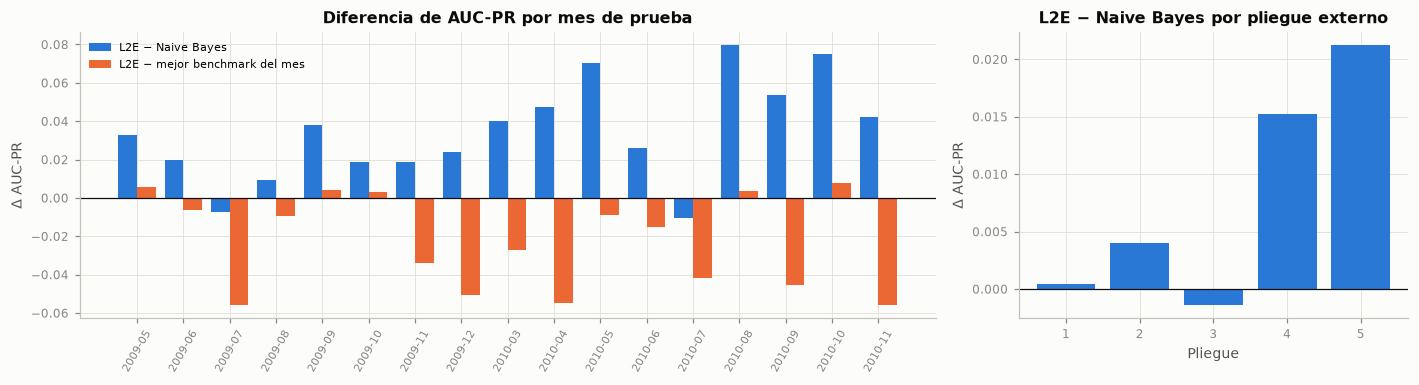

**Interpretación.** El 84 % de las 49 combinaciones de $(q_u, q_\beta)$ supera al mejor benchmark en la prueba y el 71 % en el bucle externo; el AUC-PR de prueba varía entre 0,545 y 0,602 en todo el rango de λ. Con las cuatro semillas del optimizador, el AUC-PR de prueba va de 0,593 a 0,603 y el externo de 0,1068 a 0,1107. La ventaja se reduce con la demora de las etiquetas: el AUC-PR pasa de 0,602 con un día a 0,576 con 20 y 0,578 con 40, todavía por encima del mejor benchmark estático (0,548). Con solo el 25 % más reciente del entrenamiento, el L2E obtiene 0,604, frente a 0,353 de la referencia del E2; con un 20 % de etiquetas volteadas en el ajuste conserva 0,596. Por meses, el L2E supera a Naive Bayes en 15 de 17 meses y al mejor benchmark de cada mes en 5.

Así mismo, el resultado no depende de un punto afortunado del espacio de hiperparámetros ni de la semilla: la región en la que el L2E supera al mejor benchmark es amplia y la variabilidad entre semillas es menor que la ventaja, y tampoco de una ventana de entrenamiento larga: como el nivel se actualiza en línea, el modelo no necesita que el entrenamiento represente el régimen futuro, algo que sí necesita un modelo estático. Depende, en cambio, de una condición operativa: que las etiquetas lleguen pronto. Con demoras de varias semanas el nivel filtrado envejece y parte de la ventaja se pierde, lo que coincide con el mecanismo descrito. El análisis por meses muestra dónde no gana: en los meses en los que el mejor modelo estático ordena mejor a los clientes, la ventaja del nivel no compensa.

Por esta razón, lo indicado es declarar como condición de uso del L2E un retardo de etiquetas de pocos días y vigilar en producción la diferencia entre la tasa filtrada y la observada, que es la señal de que el nivel dejó de seguir al proceso.

In [24]:
sens_q = pd.read_parquet(ANA / "sensibilidad_q.parquet")
sens_l = pd.read_parquet(ANA / "sensibilidad_lam.parquet")
ret = pd.read_parquet(ANA / "retardo.parquet")
ruido = pd.read_parquet(ANA / "ruido.parquet")
tam = pd.read_parquet(ANA / "tamano.parquet")

fig, axs = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1.15, 1.15, 1, 1]})
for ax, col, tit, ref_v in ((axs[0], "auc_pr_externo", "AUC-PR externo (sin reoptimizar)", ext[MEJOR].mean()),
                            (axs[1], "auc_pr_prueba", "AUC-PR de prueba", ap_te[mejor_te])):
    M_ = sens_q.pivot_table(index="q_pendiente", columns="q_nivel", values=col)
    im = ax.imshow(M_.to_numpy(), cmap=CMAP_SEQ, aspect="auto", origin="lower")
    ax.set_xticks(range(M_.shape[1]), [num_c(v) for v in M_.columns], rotation=45)
    ax.set_yticks(range(M_.shape[0]), [num_c(v) for v in M_.index])
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            v_ = M_.iloc[i, j]
            ax.text(j, i, num(v_, 3), ha="center", va="center", fontsize=6.5,
                    color="white" if v_ > M_.to_numpy().mean() + M_.to_numpy().std() else TINTA,
                    fontweight="bold" if v_ > ref_v else "normal")
    ax.set(title=f"{tit}\n(negrita: supera al mejor benchmark)", xlabel="q_u", ylabel="q_β")
    ax.grid(False)
axs[2].semilogx(sens_l["lam"], sens_l["auc_pr_prueba"], marker="o", color=TINTA, label="prueba")
axs[2].semilogx(sens_l["lam"], sens_l["auc_pr_externo"] * (sens_l["auc_pr_prueba"].mean() / sens_l["auc_pr_externo"].mean()),
                marker="s", color=GRIS, ls="--", label="externo (reescalado)")
axs[2].axhline(ap_te[mejor_te], color=AZUL, ls=":", lw=1.2, label=f"mejor benchmark ({CORTO[mejor_te]})")
axs[2].set(title="Sensibilidad a λ", xlabel="λ", ylabel="AUC-PR de prueba")
axs[2].legend(fontsize=7)
for (mod_, g), col in zip(ret.groupby("modelo"), (TINTA, GRIS)):
    axs[3].semilogx(g["retardo"], g["auc_pr"], marker="o", color=col, label=mod_)
axs[3].axhline(ap_te[mejor_te], color=AZUL, ls=":", lw=1.2, label="mejor benchmark estático")
axs[3].set(title="Demora de las etiquetas", xlabel="Retardo (días de contacto)", ylabel="AUC-PR de prueba")
axs[3].legend(fontsize=7)
plt.tight_layout()
plt.show()

sem = pd.DataFrame([{"Semilla del optimizador": s, "AUC-PR externo": np.mean([c["auc_pr"] for c in (corr["l2e"] if s == SEED else corr_sem[s])]),
                     "AUC-PR prueba": (L2E if s == SEED else fin_sem[s])["auc_pr"],
                     "AUC prueba": (L2E if s == SEED else fin_sem[s])["auc"]} for s in (SEED, 1, 2, 3)])
tabla(sem, dec=4, indice=False)
r_piv = ruido.pivot_table(index="ruido", columns="modelo", values="auc_pr", sort=False)
r_piv.index = [pct(v, 0) for v in r_piv.index]
tabla(r_piv.rename_axis("Etiquetas volteadas"), dec=3)
t_piv = tam.pivot_table(index=["fraccion", "registros"], columns="modelo", values="auc_pr", sort=False)
t_piv.index = [f"{pct(f_, 0)} ({num(n_)} registros)" for f_, n_ in t_piv.index]
tabla(t_piv.rename_axis("Ventana de entrenamiento más reciente"), dec=3)

# Análisis de errores: ventaja del L2E por mes de prueba y por pliegue externo
dif_mes = (M_mes_te["L2E"] - M_mes_te[MEJOR]).rename("frente a la mejor combinación")
mejor_estatico_mes = M_mes_te.drop(columns="L2E").max(axis=1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
xx = np.arange(len(M_mes_te))
axs[0].bar(xx - 0.2, dif_mes, 0.4, color=AZUL, label=f"L2E − {CORTO[MEJOR]}")
axs[0].bar(xx + 0.2, M_mes_te["L2E"] - mejor_estatico_mes, 0.4, color=NARANJA, label="L2E − mejor benchmark del mes")
axs[0].axhline(0, color=TINTA, lw=0.8)
axs[0].set_xticks(xx, M_mes_te.index, rotation=60, fontsize=7)
axs[0].set(title="Diferencia de AUC-PR por mes de prueba", ylabel="Δ AUC-PR")
axs[0].legend(fontsize=7)
axs[1].bar(M_pl.index, M_pl["L2E"] - M_pl[MEJOR], color=AZUL)
axs[1].axhline(0, color=TINTA, lw=0.8)
axs[1].set(title=f"L2E − {CORTO[MEJOR]} por pliegue externo", xlabel="Pliegue", ylabel="Δ AUC-PR")
plt.tight_layout()
plt.show()

frac_q = (sens_q["auc_pr_prueba"] > ap_te[mejor_te]).mean()
para_guion("robustez", {"frac_q": float((sens_q["auc_pr_prueba"] > ap_te[mejor_te]).mean()),
                        "retardo_1": float(ret[(ret["modelo"] == "L2E") & (ret["retardo"] == 1)]["auc_pr"].iloc[0]),
                        "retardo_40": float(ret[(ret["modelo"] == "L2E") & (ret["retardo"] == 40)]["auc_pr"].iloc[0]),
                        "sem_min": float(sem["AUC-PR prueba"].min()), "sem_max": float(sem["AUC-PR prueba"].max()),
                        "meses_gana_mejor": int((M_mes_te["L2E"] > M_mes_te[MEJOR]).sum()), "meses": int(len(M_mes_te))})
frac_q_ext = (sens_q["auc_pr_externo"] > ext[MEJOR].mean()).mean()
r1 = ret[ret["modelo"] == "L2E"].set_index("retardo")["auc_pr"]
tam_l = tam[tam["modelo"] == "L2E"].set_index("fraccion")["auc_pr"]
tam_r = tam[tam["modelo"] == "Referencia E2"].set_index("fraccion")["auc_pr"]
interpretar(
    f"El {pct(frac_q, 0)} de las {len(sens_q)} combinaciones de $(q_u, q_\\beta)$ supera al mejor benchmark en la prueba y "
    f"el {pct(frac_q_ext, 0)} en el bucle externo; el AUC-PR de prueba varía entre {num(sens_l['auc_pr_prueba'].min(), 3)} y "
    f"{num(sens_l['auc_pr_prueba'].max(), 3)} en todo el rango de λ. Con las cuatro semillas del optimizador, el AUC-PR "
    f"de prueba va de {num(sem['AUC-PR prueba'].min(), 3)} a {num(sem['AUC-PR prueba'].max(), 3)} y el externo de "
    f"{num(sem['AUC-PR externo'].min(), 4)} a {num(sem['AUC-PR externo'].max(), 4)}. La ventaja se reduce con la "
    f"demora de las etiquetas: el AUC-PR pasa de {num(r1.iloc[0], 3)} con un día a {num(r1.loc[20], 3)} con 20 y "
    f"{num(r1.iloc[-1], 3)} con 40, {'todavía por encima' if r1.iloc[-1] > ap_te[mejor_te] else 'por debajo'} del mejor "
    f"benchmark estático ({num(ap_te[mejor_te], 3)}). Con solo el 25 % más reciente del entrenamiento, el L2E obtiene "
    f"{num(tam_l.loc[0.25], 3)}, frente a {num(tam_r.loc[0.25], 3)} de la referencia del E2; con un 20 % de etiquetas "
    f"volteadas en el ajuste conserva {num(ruido[(ruido['ruido'] == 0.2) & ruido['modelo'].str.contains('solo')]['auc_pr'].iloc[0], 3)}. Por meses, el L2E supera a {CORTO[MEJOR]} en {int((dif_mes > 0).sum())} de "
    f"{len(dif_mes)} meses y al mejor benchmark de cada mes en {int((M_mes_te['L2E'] > mejor_estatico_mes).sum())}.",
    conectar("Así mismo,", "El resultado no depende de un punto afortunado del espacio de hiperparámetros ni de la semilla: "
             "la región en la que el L2E supera al mejor benchmark es amplia y la variabilidad entre semillas es menor "
             "que la ventaja, y tampoco de una ventana de entrenamiento larga: como el nivel se actualiza en línea, "
             "el modelo no necesita que el entrenamiento represente el régimen futuro, algo que sí necesita un modelo "
             "estático. Depende, en cambio, de una condición operativa: que las etiquetas lleguen pronto. Con demoras de "
             "varias semanas el nivel filtrado envejece y parte de la ventaja se pierde, lo que coincide con el "
             "mecanismo descrito. El análisis por meses muestra dónde no gana: en los meses en los que el mejor "
             "modelo estático ordena mejor a los clientes, la ventaja del nivel no compensa."),
    conectar("Por esta razón, lo indicado es", "Declarar como condición de uso del L2E un retardo de etiquetas de pocos "
             "días y vigilar en producción la diferencia entre la tasa filtrada y la observada, que es la señal de que "
             "el nivel dejó de seguir al proceso."))

(sec-6-10)=
## 6.10 Evaluación amplia: tres conjuntos de datos adicionales

La guía pide al menos tres conjuntos adicionales de la misma tarea y de naturaleza distinta, con las mismas particiones para todos los modelos y el mismo presupuesto de optimización. Se eligieron tres problemas públicos de clasificación binaria con orden temporal y etiquetas que se conocen pronto: retrasos de vuelos (*airlines*), subidas del precio de la electricidad (*electricity*) y días de ozono alto (*ozone*). Para cada uno se ejecuta la validación anidada cronológica 5 × 3 con los 7 finalistas de Bank Marketing (mismo balanceo y optimizador) y tres variantes del L2E (completo, sin actualizar pendientes y estático). El cuadro describe además la autocorrelación del nivel diario, que es la estructura que explota el L2E.

In [25]:
from bm.adicionales import cargar, resumen_conjunto

desc = pd.DataFrame([{**resumen_conjunto(cargar(n)), "Dominio": DESC_ADIC[n]["dominio"],
                      "Objetivo": DESC_ADIC[n]["objetivo"], "Fuente": DESC_ADIC[n]["fuente"]} for n in DESC_ADIC])
desc = pd.concat([pd.DataFrame([{"conjunto": "bank marketing", "registros": len(X_tr), "predictoras": 17,
                                 "dias": n_dias_tr, "registros_por_dia": float(pd.Series(dia_tr).value_counts().median()),
                                 "prevalencia": y_tr.mean(), "autocorr_1": float(fac[1]), "gap": GAP,
                                 "Dominio": "Telemercadeo bancario", "Objetivo": "el cliente suscribe (y = yes)",
                                 "Fuente": "Moro, Cortez y Rita (2014); UCI"}]), desc], ignore_index=True)
tabla(desc.rename(columns={"conjunto": "Conjunto", "registros": "Registros", "predictoras": "Predictoras", "dias": "Días",
                           "registros_por_dia": "Registros por día", "prevalencia": "Prevalencia",
                           "autocorr_1": "Autocorrelación del nivel diario", "gap": "Separación"}), dec=3, indice=False)

adic["Modelo"] = np.where(adic["modelo"] == "original", "L2E · " + adic["variante"].fillna("").map(
    {"l2e": "completo", "sin_pendientes": "sin pendientes", "estatico": "estático"}), adic["modelo"].map(CORTO))
banco = pd.concat([pd.DataFrame({"conjunto": "bank marketing", "Modelo": CORTO[m], "pliegue": range(5), "auc_pr": ext[m]})
                   for m in MODELOS] +
                  [pd.DataFrame({"conjunto": "bank marketing", "Modelo": f"L2E · {n}", "pliegue": range(5),
                                 "auc_pr": [c["auc_pr"] for c in corr[v]]})
                   for v, n in (("l2e", "completo"), ("sin_pendientes", "sin pendientes"), ("estatico", "estático"))])
todo_ad = pd.concat([banco, adic[["conjunto", "Modelo", "pliegue", "auc_pr"]]], ignore_index=True)
med = todo_ad.pivot_table(index="Modelo", columns="conjunto", values="auc_pr", aggfunc="mean")
de = todo_ad.pivot_table(index="Modelo", columns="conjunto", values="auc_pr", aggfunc="std")
rk = med.rank(ascending=False)
celdas = med.copy().astype(object)
for c in med.columns:
    celdas[c] = [f"{num(m_, 3)} ± {num(d_, 3)} ({int(r_)}.º)" for m_, d_, r_ in zip(med[c], de[c], rk[c])]
celdas["Rango medio"] = rk.mean(axis=1)
celdas = celdas.sort_values("Rango medio")
tabla(celdas, dec=2)

bloques = todo_ad.pivot_table(index=["conjunto", "pliegue"], columns="Modelo", values="auc_pr")
w_ad = []
for c in bloques.columns.drop("L2E · completo"):
    w_ad.append({"Frente a": c, "Bloques": len(bloques), "Diferencia mediana": (bloques["L2E · completo"] - bloques[c]).median(),
                 "p Wilcoxon": stats.wilcoxon(bloques["L2E · completo"], bloques[c]).pvalue,
                 "δ de Cliff": st.delta_cliff(bloques["L2E · completo"], bloques[c])})
w_ad = pd.DataFrame(w_ad)
w_ad["p Holm"] = st.ajustar_p(w_ad["p Wilcoxon"])
tabla(w_ad.assign(**{"p Wilcoxon": w_ad["p Wilcoxon"].map(pval), "p Holm": w_ad["p Holm"].map(pval)}), dec=3, indice=False)

gana = {c: med[c].idxmax() for c in med.columns}
para_guion("adicionales_rangos", rk.reset_index())
para_guion("adicionales_medias", med.reset_index())
sig_ad = [r_["Frente a"] for _, r_ in w_ad.iterrows() if r_["p Holm"] < 0.05 and r_["Diferencia mediana"] > 0]
r_l2e = rk.loc["L2E · completo"]
interpretar(
    f"En los conjuntos adicionales el L2E completo queda {enumerar([f'{int(r_l2e[c])}.º en {c}' for c in med.columns if c != 'bank marketing'])}, "
    f"mientras que en Bank Marketing es {int(r_l2e['bank marketing'])}.º. El mejor modelo es "
    f"{enumerar([f'{gana[c]} en {c}' for c in med.columns if c != 'bank marketing'])}. En *electricity*, cuyo nivel "
    f"diario casi no tiene autocorrelación ({num(desc.set_index('conjunto').loc['electricity', 'autocorr_1'], 2)}), el L2E "
    f"estático supera al completo ({num(med.loc['L2E · estático', 'electricity'], 3)} frente a "
    f"{num(med.loc['L2E · completo', 'electricity'], 3)}). Sobre los {len(bloques)} bloques (conjunto × pliegue), "
    + (f"la única comparación significativa tras Holm es la de {enumerar(sig_ad)}." if len(sig_ad) == 1 else
       f"las comparaciones significativas tras Holm son las de {enumerar(sig_ad)}." if sig_ad else
       "ninguna comparación favorable al L2E es significativa tras Holm."),
    conectar("Hay que tener en cuenta que", "La ventaja del L2E no es general, y eso es coherente con su diseño: el modelo "
             "aporta cuando hay un nivel latente persistente que las variables no explican, como en el telemercadeo "
             "bancario, donde cada día refleja una lista de clientes y un contexto de campaña distintos. Las explicaciones "
             "plausibles, no verificadas aquí, son que en *airlines* parte del patrón diario ya lo recoge `DayOfWeek` y "
             "los modelos no lineales (bosques y XGBoost) aprovechan interacciones que una logística no tiene, y que en "
             "*ozone*, con un solo registro por día, el nivel se confunde con el ruido de cada observación. En "
             "*electricity*, lo que sí se verificó es que la desventaja del modelo completo "
             "se concentra en el primer pliegue, donde la validación interna, con apenas 75 días de ajuste, eligió un "
             "$q_u$ alto que hizo que el nivel persiguiera ruido."),
    conectar("Por tal motivo, se opta por", "Delimitar la afirmación de superioridad al problema de aplicación (condición "
             "R3) y presentar estos resultados como el límite de validez del modelo: el L2E es una herramienta para "
             "problemas de propensión con nivel latente persistente, no un clasificador general. Una alternativa para "
             "que una validación interna pequeña no elija una dinámica inexistente es estimar $q_u$ por Bayes empírico; "
             "la sección 6.13 la evalúa (mejora M2) y muestra que en Bank Marketing empeora el resultado, de modo que la "
             "elección de $q_u$ con ventanas cortas queda como limitación (sección 8.3)."))

Conjunto,Registros,Predictoras,Días,Registros por día,Prevalencia,Autocorrelación del nivel diario,Separación,Dominio,Objetivo,Fuente
bank marketing,32 940,17,166,"191,500","0,064","0,759",507,Telemercadeo bancario,el cliente suscribe (y = yes),"Moro, Cortez y Rita (2014); UCI"
airlines,21 700,6,31,"700,000","0,445","0,673",700,Transporte aéreo,el vuelo se retrasa (Delay = 1),"Ikonomovska (2009), Data Expo de la ASA; OpenML 1169"
electricity,21 600,7,450,"48,000","0,420","0,094",48,Mercado eléctrico,el precio de Nueva Gales del Sur sube frente a la media de 24 h (UP),Harries (1999); OpenML 151
ozone,2 534,72,2 534,"1,000","0,063","0,286",1,Calidad del aire,día con ozono alto (umbral de 8 horas),"Zhang y Fan (2008), UCI; OpenML 1487"


conjunto,airlines,bank marketing,electricity,ozone,Rango medio
Modelo,,,,,
L2E · estático,"0,643 ± 0,100 (3.º)","0,096 ± 0,087 (4.º)","0,793 ± 0,106 (1.º)","0,378 ± 0,134 (6.º)","3,50"
SVM,"0,642 ± 0,092 (4.º)","0,092 ± 0,091 (7.º)","0,774 ± 0,127 (3.º)","0,446 ± 0,116 (1.º)","3,75"
Random Forest,"0,652 ± 0,092 (1.º)","0,095 ± 0,092 (6.º)","0,720 ± 0,111 (7.º)","0,413 ± 0,129 (3.º)","4,25"
L2E · completo,"0,634 ± 0,096 (7.º)","0,111 ± 0,116 (2.º)","0,758 ± 0,199 (5.º)","0,384 ± 0,152 (5.º)","4,75"
L2E · sin pendientes,"0,633 ± 0,094 (8.º)","0,115 ± 0,097 (1.º)","0,761 ± 0,192 (4.º)","0,377 ± 0,128 (7.º)","5,00"
Logística L1/L2,"0,634 ± 0,096 (6.º)","0,096 ± 0,096 (5.º)","0,783 ± 0,115 (2.º)","0,355 ± 0,147 (8.º)","5,25"
XGBoost,"0,650 ± 0,092 (2.º)","0,091 ± 0,077 (8.º)","0,717 ± 0,120 (8.º)","0,403 ± 0,144 (4.º)","5,50"
KNN,"0,639 ± 0,095 (5.º)","0,084 ± 0,067 (10.º)","0,702 ± 0,124 (9.º)","0,417 ± 0,154 (2.º)","6,50"
Naive Bayes,"0,628 ± 0,098 (9.º)","0,103 ± 0,108 (3.º)","0,725 ± 0,143 (6.º)","0,296 ± 0,159 (9.º)","6,75"


Frente a,Bloques,Diferencia mediana,p Wilcoxon,δ de Cliff,p Holm
KNN,20,"0,005","0,312","0,060","1,000"
L2E · estático,20,"-0,000","0,956","-0,010","1,000"
L2E · sin pendientes,20,"0,000","0,756","-0,020","1,000"
Logística L1/L2,20,"0,002","0,312","0,040","1,000"
Naive Bayes,20,"0,018","0,007","0,100","0,058"
Random Forest,20,"0,001","0,841","0,040","1,000"
SVM,20,"-0,004","0,475","-0,010","1,000"
XGBoost,20,"0,003","0,701","0,045","1,000"
Árbol de decisión,20,"0,051","< 0,001","0,185","0,004"


**Interpretación.** En los conjuntos adicionales el L2E completo queda 7.º en airlines, 5.º en electricity y 5.º en ozone, mientras que en Bank Marketing es 2.º. El mejor modelo es Random Forest en airlines, L2E · estático en electricity y SVM en ozone. En *electricity*, cuyo nivel diario casi no tiene autocorrelación (0,09), el L2E estático supera al completo (0,793 frente a 0,758). Sobre los 20 bloques (conjunto × pliegue), la única comparación significativa tras Holm es la de Árbol de decisión.

Hay que tener en cuenta que la ventaja del L2E no es general, y eso es coherente con su diseño: el modelo aporta cuando hay un nivel latente persistente que las variables no explican, como en el telemercadeo bancario, donde cada día refleja una lista de clientes y un contexto de campaña distintos. Las explicaciones plausibles, no verificadas aquí, son que en *airlines* parte del patrón diario ya lo recoge `DayOfWeek` y los modelos no lineales (bosques y XGBoost) aprovechan interacciones que una logística no tiene, y que en *ozone*, con un solo registro por día, el nivel se confunde con el ruido de cada observación. En *electricity*, lo que sí se verificó es que la desventaja del modelo completo se concentra en el primer pliegue, donde la validación interna, con apenas 75 días de ajuste, eligió un $q_u$ alto que hizo que el nivel persiguiera ruido.

Por tal motivo, se opta por delimitar la afirmación de superioridad al problema de aplicación (condición R3) y presentar estos resultados como el límite de validez del modelo: el L2E es una herramienta para problemas de propensión con nivel latente persistente, no un clasificador general. Una alternativa para que una validación interna pequeña no elija una dinámica inexistente es estimar $q_u$ por Bayes empírico; la sección {ref}`6.13 <sec-6-13>` la evalúa (mejora M2) y muestra que en Bank Marketing empeora el resultado, de modo que la elección de $q_u$ con ventanas cortas queda como limitación (sección {ref}`8.3 <sec-8-3>`).

(sec-6-11)=
## 6.11 Interpretabilidad: SHAP del L2E frente a los benchmarks

En el L2E el logit es lineal en las predictoras dado el estado del día, así que los valores SHAP son **exactos**: $\phi_{ij} = \beta_{t(i), j} (x_{ij} - \bar x_j)$, con las pendientes vigentes el día de la predicción, más un término propio del modelo, el **nivel latente del día**, que es la diferencia entre el logit esperado de ese día y su promedio en la prueba. Se comparan con los SHAP exactos de la referencia del Entregable 2 (también lineal) y con los SHAP por permutaciones de la mejor combinación benchmark, todos en escala logit.

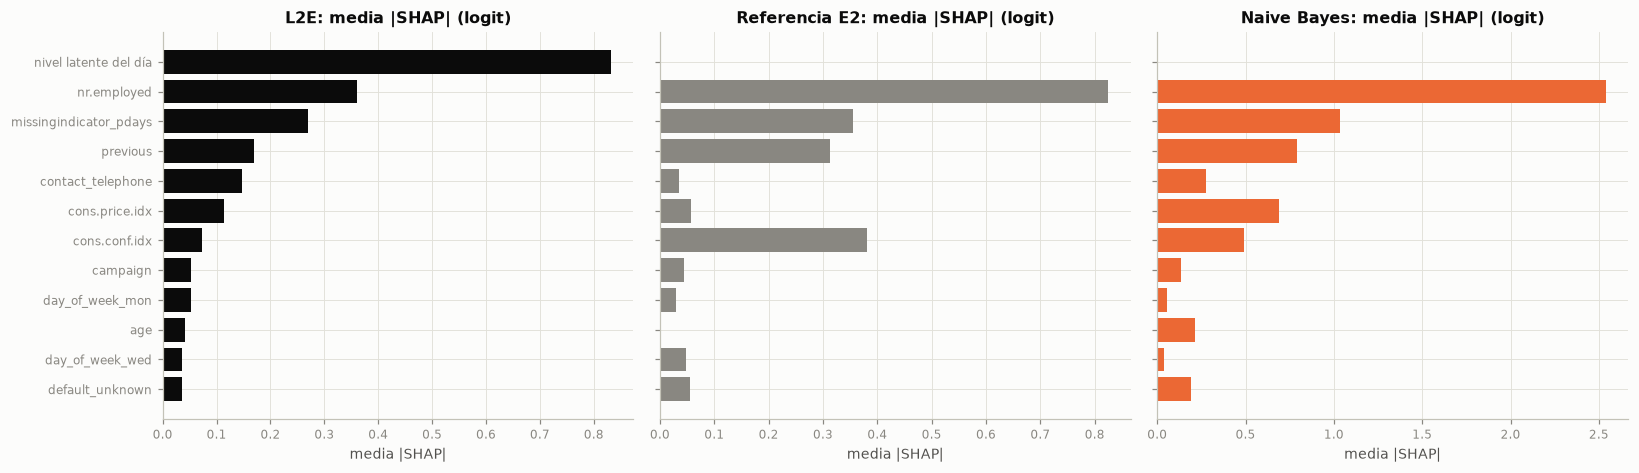

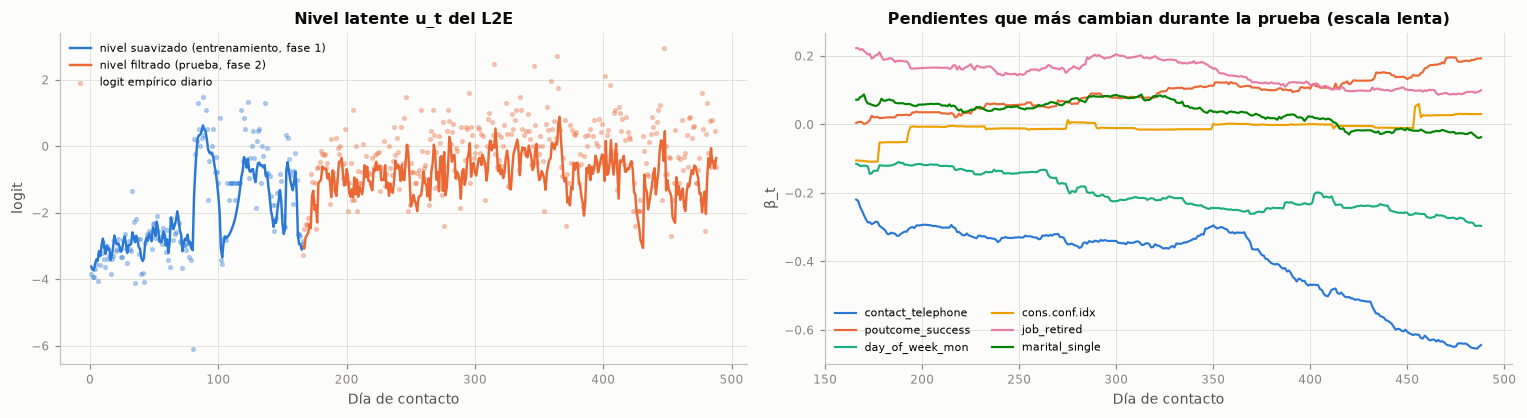

**Interpretación.** En el L2E, el componente más importante es el nivel latente del día (media |SHAP| de 0,832 en logit), seguido de `nr.employed`, `missingindicator_pdays` y `previous`. El orden de importancia de las variables del cliente coincide en buena parte con el de la referencia del E2 (correlación de Spearman de 0,78) y con el de Naive Bayes (0,77). Durante la prueba, la pendiente que más cambia es la de `contact_telephone` (0,424 en logit).

De esta forma, el L2E no reemplaza la lectura de las variables que ya tenía el proyecto: conserva lo que una logística regularizada aprende del cliente (`nr.employed`, `missingindicator_pdays` y `previous`) y agrega, de forma explícita y medible, el término que los benchmarks no tienen. La trayectoria del nivel reproduce el salto de 2009 y la tasa alta de 2010 a partir de las etiquetas de los días cerrados, como complemento de lo que ya indican las variables macroeconómicas como `nr.employed`, y las pendientes cambian despacio, como supone la escala lenta. Esa separación hace al modelo más interpretable que un ensamble: cada predicción se descompone en *qué tan bueno es el día* y *qué tan bueno es el cliente dentro del día*.

En consecuencia, se decide mostrar en el dashboard las dos partes de la explicación local (nivel del día y contribuciones del cliente) y la trayectoria del nivel como diagnóstico del modelo en producción.

In [26]:
sh_l = pd.read_parquet(ANA / "shap_l2e.parquet").drop(columns="_base")
sh_r = pd.read_parquet(ANA / "shap_referencia.parquet").drop(columns="_base")
sh_n = pd.read_parquet(ANA / "shap_naive_bayes.parquet").drop(columns="_base")
imp = pd.DataFrame({"L2E": sh_l.abs().mean(), "Referencia E2": sh_r.abs().mean(), CORTO[MEJOR]: sh_n.abs().mean()})
comunes = imp.dropna().index
rho_r = stats.spearmanr(imp.loc[comunes, "L2E"], imp.loc[comunes, "Referencia E2"]).statistic
rho_n = stats.spearmanr(imp.loc[comunes, "L2E"], imp.loc[comunes, CORTO[MEJOR]]).statistic
top = imp["L2E"].sort_values(ascending=False).head(12).index

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, col, color in zip(axs, imp.columns, (TINTA, GRIS, COLOR[MEJOR])):
    ax.barh(range(len(top)), imp.loc[top, col].fillna(0), color=color)
    ax.set(title=f"{col}: media |SHAP| (logit)", xlabel="media |SHAP|")
axs[0].set_yticks(range(len(top)), top)
axs[0].invert_yaxis()
plt.tight_layout()
plt.show()

traza = L2E["traza"]
mod_l2e = L2E["pipeline"][-1]
nombres = [c.split("__", 1)[-1] for c in L2E["pipeline"][:-1].get_feature_names_out()][:-1]
B_t = pd.DataFrame(traza["pendientes"], columns=nombres, index=traza["dia"])
cambio = (B_t.iloc[-1] - B_t.iloc[0]).abs().sort_values(ascending=False)
obs_te = pd.DataFrame({"d": dia_te, "y": yte}).groupby("d")["y"].agg(["sum", "size"])
fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
axs[0].plot(mod_l2e.dias_, mod_l2e.nivel_, color=AZUL, lw=1.6, label="nivel suavizado (entrenamiento, fase 1)")
axs[0].plot(traza["dia"], traza["nivel"], color=NARANJA, lw=1.6, label="nivel filtrado (prueba, fase 2)")
axs[0].scatter(g_tr.index, g_tr["logit"], s=6, color=AZUL, alpha=0.3)
axs[0].scatter(obs_te.index, np.log((obs_te["sum"] + 0.5) / (obs_te["size"] - obs_te["sum"] + 0.5)), s=6, color=NARANJA, alpha=0.3,
               label="logit empírico diario")
axs[0].set(title="Nivel latente u_t del L2E", xlabel="Día de contacto", ylabel="logit")
axs[0].legend(fontsize=7)
for c, col in zip(cambio.index[:6], CAT):
    axs[1].plot(B_t.index, B_t[c], color=col, lw=1.4, label=c)
axs[1].set(title="Pendientes que más cambian durante la prueba (escala lenta)", xlabel="Día de contacto",
           ylabel="β_t")
axs[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

top3 = imp["L2E"].drop("nivel latente del día").sort_values(ascending=False).head(3).index
para_guion("shap", {"nivel": float(imp.loc["nivel latente del día", "L2E"]), "top3": list(top3), "rho_ref": float(rho_r),
                    "rho_nb": float(rho_n), "cambio_var": cambio.index[0], "cambio": float(cambio.iloc[0])})
interpretar(
    f"En el L2E, el componente más importante es el nivel latente del día (media |SHAP| de "
    f"{num(imp.loc['nivel latente del día', 'L2E'], 3)} en logit), seguido de {enumerar([f'`{c}`' for c in top3])}. "
    f"El orden de importancia de las variables del cliente coincide en buena parte con el de la referencia del E2 "
    f"(correlación de Spearman de {num(rho_r, 2)}) y con el de {CORTO[MEJOR]} ({num(rho_n, 2)}). Durante la prueba, "
    f"la pendiente que más cambia es la de `{cambio.index[0]}` ({num(cambio.iloc[0], 3)} en logit).",
    conectar("De esta forma,", "El L2E no reemplaza la lectura de las variables que ya tenía el proyecto: conserva lo que "
             f"una logística regularizada aprende del cliente ({enumerar([f'`{c}`' for c in top3])}) y agrega, de forma explícita y medible, el término que los benchmarks no tienen. La trayectoria "
             "del nivel reproduce el salto de 2009 y la tasa alta de 2010 a partir de las etiquetas de los días "
             "cerrados, como complemento de lo que ya indican las variables macroeconómicas como `nr.employed`, y las "
             "pendientes cambian despacio, como supone la escala lenta. Esa separación hace al modelo más "
             "interpretable que un ensamble: cada predicción se descompone en *qué tan bueno es el día* y *qué tan "
             "bueno es el cliente dentro del día*."),
    conectar("En consecuencia, se decide", "Mostrar en el dashboard las dos partes de la explicación local (nivel del día "
             "y contribuciones del cliente) y la trayectoria del nivel como diagnóstico del modelo en producción."))

In [27]:
n_r3_mejor = n_r3
cliff_mejor = w_te.loc[MEJOR, "δ de Cliff"]
c1 = all(ext["L2E"].mean() > ext[m].mean() for m in MODELOS)
c2 = n_r3_mejor >= 3
c3 = abs(cliff_mejor) >= 0.147
veredicto = pd.DataFrame([
    {"Condición": "R1. Novedad en la aplicación", "Evidencia": f"Revisión en {n_bases} bases y {n_cadenas} cadenas (sección 4): "
     "ninguna intersección modelo × problema; el antecedente más cercano usa otra familia", "Cumple": "Sí"},
    {"Condición": "R2. Implementación algorítmica propia", "Evidencia": "Clase propia compatible con scikit-learn, Newton por "
     "bloques y filtro de Laplace programados con numpy y scipy, 6 propiedades demostradas y pruebas unitarias (sección 5)",
     "Cumple": "Sí" if n_pasan == len(pruebas_u) else "Revisar"},
    {"Condición": "R3.1 Media externa mayor que la de los 7 finalistas",
     "Evidencia": f"{ms(ext['L2E'])} frente a {ms(ext[MEJOR])} de {CORTO[MEJOR]}", "Cumple": "Sí" if c1 else "No"},
    {"Condición": "R3.2 Al menos tres pruebas con p ajustado < 0,05 (frente a la mejor combinación)",
     "Evidencia": f"{n_r3_mejor} de 4 pruebas declaradas (sección 6.7)", "Cumple": "Sí" if c2 else "No"},
    {"Condición": "R3.3 |δ de Cliff| ≥ 0,147", "Evidencia": f"δ = {num(cliff_mejor, 3)} sobre los meses de prueba "
     f"({st.magnitud_cliff(cliff_mejor)})", "Cumple": "Sí" if c3 else "No"},
])
display(Markdown("### 6.12 Veredicto sobre las condiciones R1, R2 y R3"))
tabla(veredicto, indice=False)
r3 = c1 and c2 and c3
(RES / "mejoras").mkdir(parents=True, exist_ok=True)
(RES / "mejoras" / "resumen_r3.json").write_text(json.dumps({
    "mejor": MEJOR, "n_r3": n_r3_mejor, "cliff": float(cliff_mejor), "r3": bool(r3), "c1": bool(c1),
    "ext_l2e": float(ext["L2E"].mean()), "ext_l2e_de": float(ext["L2E"].std(ddof=1)),
    "ext_mejor": float(ext[MEJOR].mean()), "ext_mejor_de": float(ext[MEJOR].std(ddof=1)),
    "sig_meses": sig_te, "n_benchmarks": len(COMP) - 1, "ganancia_ap": float(bt_ap.set_index("modelo").loc[MEJOR, "diferencia"]),
    "control_c2": {"modelo": mejor_c["Modelo"], "variante": mejor_c["Variante"], "auc_pr": float(mejor_c["AUC-PR"]),
                   "dif": float(bt_c["diferencia"]), "p": float(bt_c["p"])}}, ensure_ascii=False, indent=1), encoding="utf-8")
display(Markdown(
    f"**Veredicto.** El L2E cumple R1 y R2 y {'cumple' if r3 else 'no cumple'} R3 según la definición operativa de la "
    "guía, evaluada frente a la mejor combinación benchmark. La superioridad es sólida en el ordenamiento global de la "
    "prueba frente a todos los benchmarks (*bootstrap* y permutación por días) y, dentro de cada mes, frente a "
    f"{enumerar(sig_te)}; frente a "
    f"{enumerar([CORTO[k] for k in COMP[1:] if CORTO[k] not in sig_te])}, el L2E no es superior dentro de cada periodo, y en los tres conjuntos adicionales tampoco es "
    "el mejor modelo. Estos matices delimitan la afirmación y se discuten en la sección 8."))

(sec-6-12)=
## 6.12 Veredicto sobre las condiciones R1, R2 y R3

Condición,Evidencia,Cumple
R1. Novedad en la aplicación,Revisión en 4 bases y 10 cadenas (sección 4): ninguna intersección modelo × problema; el antecedente más cercano usa otra familia,Sí
R2. Implementación algorítmica propia,"Clase propia compatible con scikit-learn, Newton por bloques y filtro de Laplace programados con numpy y scipy, 6 propiedades demostradas y pruebas unitarias (sección 5)",Sí
R3.1 Media externa mayor que la de los 7 finalistas,"0,111 ± 0,116 frente a 0,103 ± 0,108 de Naive Bayes",Sí
"R3.2 Al menos tres pruebas con p ajustado < 0,05 (frente a la mejor combinación)",3 de 4 pruebas declaradas (sección 6.7),Sí
"R3.3 |δ de Cliff| ≥ 0,147","δ = 0,156 sobre los meses de prueba (pequeño)",Sí


**Veredicto.** El L2E cumple R1 y R2 y cumple R3 según la definición operativa de la guía, evaluada frente a la mejor combinación benchmark. La superioridad es sólida en el ordenamiento global de la prueba frente a todos los benchmarks (*bootstrap* y permutación por días) y, dentro de cada mes, frente a Naive Bayes, XGBoost y Árbol de decisión; frente a Logística L1/L2, Random Forest, SVM, KNN y Referencia E2, el L2E no es superior dentro de cada periodo, y en los tres conjuntos adicionales tampoco es el mejor modelo. Estos matices delimitan la afirmación y se discuten en la sección 8.

(sec-6-13)=
## 6.13 Mejoras y ajustes evaluados después del modelo original

Después del veredicto se buscó mejorar los resultados con técnicas aceptadas en *machine learning*, con una regla declarada antes de ejecutar: cada cambio pasa por la misma validación anidada (mismos pliegues, Optuna y 20 configuraciones) y **solo se adopta si su AUC-PR medio del bucle externo supera al del L2E en más que la variabilidad entre semillas del optimizador (0,004)**. La prueba se informa como referencia y no decide. Se evaluaron dos grupos: cinco ajustes para que los modelos de árboles toleren el cambio de régimen (`scripts/ejecutar_ajustes_arboles.py`) y cinco mejoras del L2E (`scripts/ejecutar_mejoras.py`): *splines* para las variables del cliente con relación no lineal (M1), estimación de $q_u$ por Bayes empírico con la evidencia de Laplace (M2), ponderación por recencia en el ajuste (M3), ensamble con un Random Forest reentrenado cada mes (M4) y promedio de los modelos obtenidos con cuatro semillas del optimizador (M5).

In [28]:
from bm.mejoras import UMBRAL_SEMILLAS, tabla_arboles, tabla_mejoras

t_arb = tabla_arboles()
tabla(t_arb.rename(columns={"variante": "Ajuste", "diferencia": "Δ AUC-PR prueba frente al original",
                            "ic_inf": "IC 95 % inferior", "ic_sup": "IC 95 % superior", "p": "p (bootstrap por días)"}),
      dec=3, indice=False)
t_mej = tabla_mejoras()
tabla(t_mej.drop(columns="clave"), dec=4, indice=False)

adoptadas = t_mej[t_mej["Decisión"] == "Se adopta"]
m = t_mej.set_index("clave")
ta = t_arb.set_index("variante")
mejor_arbol = ta.drop(index=[i for i in ta.index if i.startswith("L2E") or i.startswith("Logística")])["AUC-PR prueba"].idxmax()
interpretar(
    f"De los ajustes para los árboles, el mejor en la prueba es «{mejor_arbol}», con un AUC-PR de "
    f"{num(ta.loc[mejor_arbol, 'AUC-PR prueba'], 4)}, frente a {num(ta.loc['L2E (modelo original)', 'AUC-PR prueba'], 4)} del "
    f"L2E, aunque en el bucle externo se queda en {num(ta.loc[mejor_arbol, 'AUC-PR externo'], 3)}. De las mejoras del L2E, "
    f"{'ninguna supera' if adoptadas.empty else f'{len(adoptadas)} superan'} el umbral de {num(UMBRAL_SEMILLAS, 3)}: M1 cambia el AUC-PR "
    f"externo en {num(m.loc['m1_splines', 'Δ externo frente al L2E'], 4)}, M3 en {num(m.loc['m3_recencia', 'Δ externo frente al L2E'], 4)}, "
    f"M4 en {num(m.loc['m4_ensamble', 'Δ externo frente al L2E'], 4)} y M5 en {num(m.loc['m5_semillas', 'Δ externo frente al L2E'], 4)}, "
    f"mientras que M2 lo reduce en {num(-m.loc['m2_bayes_empirico', 'Δ externo frente al L2E'], 4)}, con "
    f"{num(m.loc['m2_bayes_empirico', 'Último pliegue'], 3)} en el último pliegue frente a {num(m.loc['l2e', 'Último pliegue'], 3)} del L2E."
    + (f" M4 obtiene en la prueba un AUC-PR de {num(m.loc['m4_ensamble', 'AUC-PR prueba'], 3)}, mayor que el del L2E "
       f"({num(m.loc['l2e', 'AUC-PR prueba'], 3)}), pero en el bucle externo queda por debajo; por la regla declarada no se "
       "adopta, porque elegirlo por su resultado en la prueba sería usar la prueba para seleccionar el modelo."
       if m.loc["m4_ensamble", "AUC-PR prueba"] > m.loc["l2e", "AUC-PR prueba"] and
       m.loc["m4_ensamble", "Δ externo frente al L2E"] <= UMBRAL_SEMILLAS else ""),
    conectar("Lo anterior indica que", "El modelo original ya captura lo que es posible mejorar con las técnicas "
             "habituales: los efectos no lineales del cliente y la ponderación por recencia aportan menos que el ruido "
             "de la propia optimización, y los ajustes que más ayudan a los árboles son justamente los que usan las "
             "etiquetas recientes, el mecanismo del L2E. El resultado negativo de M2 es el más informativo: la evidencia "
             "de Laplace estima la dinámica del nivel con el pasado (2008, cuando casi no se movía) y produce un filtro "
             "demasiado lento para el salto de 2009, mientras que elegir $q_u$ por desempeño predictivo en la validación "
             "interna se adapta mejor cuando el futuro cambia más que el pasado."),
    conectar("Por tal motivo, se opta por", ("Conservar el L2E sin cambios como modelo final: ninguna mejora supera la "
             "regla de decisión, de modo que el veredicto de la sección 6.12 se mantiene, y reportar las diez pruebas "
             "como parte de la evidencia, incluidas las que no funcionaron.") if adoptadas.empty else
             f"Adoptar {enumerar(adoptadas['Mejora'].tolist())} y repetir con ella la validación estadística de la sección 6."))

Ajuste,AUC-PR prueba,AUC prueba,AUC-PR externo,Δ AUC-PR prueba frente al original,IC 95 % inferior,IC 95 % superior,p (bootstrap por días)
"Logística C = 0,01","0,543","0,705","0,098",—,—,—,—
Random Forest · original,"0,497","0,716","0,087",—,—,—,—
Random Forest · (a) sin macro ni month,"0,521","0,694","0,078","0,024","-0,027","0,097","0,358"
Random Forest · (b) macro relativas,"0,489","0,727","0,093","-0,007","-0,037","0,027","0,688"
Random Forest · (d) sin macro + filtro de nivel C2,"0,567","0,755","0,100","0,071","0,035","0,104","0,001"
XGBoost · original,"0,431","0,610","0,091",—,—,—,—
XGBoost · (a) sin macro ni month,"0,494","0,686","0,079","0,064","0,018","0,102","0,006"
XGBoost · (b) macro relativas,"0,482","0,698","0,092","0,051","-0,001","0,092","0,070"
XGBoost · (d) sin macro + filtro de nivel C2,"0,549","0,747","0,100","0,119","0,047","0,164","0,001"
XGBoost · (c) híbrido sobre el logit de la logística,"0,547","0,714","0,098","0,116","0,065","0,160","0,001"


Mejora,AUC-PR prueba,AUC prueba,AUC-PR externo,DE externo,Último pliegue,Δ externo frente al L2E,Decisión
L2E (modelo original),"0,6019","0,7716","0,1107","0,1156","0,3169","0,0000",Referencia
M1 · Efectos no lineales del cliente (splines en age y campaign),"0,6005","0,7732","0,1120","0,1123","0,3124","0,0013",No se adopta
M2 · q_u por Bayes empírico (máxima evidencia),"0,5952","0,7705","0,0731","0,0333","0,1297","-0,0375",No se adopta
M3 · Ponderación por recencia en el ajuste,"0,5975","0,7707","0,1118","0,1145","0,3153","0,0012",No se adopta
M4 · Ensamble con Random Forest reentrenado cada mes,"0,6126","0,7735","0,1045","0,0969","0,2769","-0,0062",No se adopta
M5 · Promedio de las cuatro semillas del optimizador,"0,6007","0,7717","0,1082","0,1165","0,3162","-0,0024",No se adopta


**Interpretación.** De los ajustes para los árboles, el mejor en la prueba es «Random Forest · (e) reentrenado cada mes», con un AUC-PR de 0,6015, frente a 0,6019 del L2E, aunque en el bucle externo se queda en 0,086. De las mejoras del L2E, ninguna supera el umbral de 0,004: M1 cambia el AUC-PR externo en 0,0013, M3 en 0,0012, M4 en -0,0062 y M5 en -0,0024, mientras que M2 lo reduce en 0,0375, con 0,130 en el último pliegue frente a 0,317 del L2E. M4 obtiene en la prueba un AUC-PR de 0,613, mayor que el del L2E (0,602), pero en el bucle externo queda por debajo; por la regla declarada no se adopta, porque elegirlo por su resultado en la prueba sería usar la prueba para seleccionar el modelo.

Lo anterior indica que el modelo original ya captura lo que es posible mejorar con las técnicas habituales: los efectos no lineales del cliente y la ponderación por recencia aportan menos que el ruido de la propia optimización, y los ajustes que más ayudan a los árboles son justamente los que usan las etiquetas recientes, el mecanismo del L2E. El resultado negativo de M2 es el más informativo: la evidencia de Laplace estima la dinámica del nivel con el pasado (2008, cuando casi no se movía) y produce un filtro demasiado lento para el salto de 2009, mientras que elegir $q_u$ por desempeño predictivo en la validación interna se adapta mejor cuando el futuro cambia más que el pasado.

Por tal motivo, se opta por conservar el L2E sin cambios como modelo final: ninguna mejora supera la regla de decisión, de modo que el veredicto de la sección {ref}`6.12 <sec-6-12>` se mantiene, y reportar las diez pruebas como parte de la evidencia, incluidas las que no funcionaron.